In [19]:
import pandas as pd
import numpy as np
import os
from glob import glob
from sklearn.metrics import roc_curve, auc, balanced_accuracy_score
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from scipy.optimize import brentq
from scipy.interpolate import interp1d
import seaborn as sns

In [23]:
def print_metrics(scores, labels):
    fpr, tpr, thres = roc_curve(labels, scores)
    rocauc = auc(fpr, tpr)
    fnr = 1 - tpr
    eer_func = interp1d(fpr, fnr)
    eer = brentq(lambda x: eer_func(x) - x, 0., 1.)

    print(f"AUC: {rocauc * 100:.2f}%, EER: {eer * 100:.2f}%")

def show_expert_contributions(contrib, contrib_norm, labels_names):
    n_exp = len(contrib)

    print("\n=== Ranked Experts ===\n")

    for i, c in sorted(enumerate(contrib), key=lambda x: -x[1]):
        name = labels_names[i]
        print(f"{i:>2} | {name:<12} | contribution: {c:>8.4f} | normalized: {contrib_norm[i]:>7.4f}")

    print("\nSummary:")
    print(f"Positive contributors: {np.sum(contrib > 0)} {np.where(contrib > 0)[0].tolist()}")
    print(f"Negative contributors: {np.sum(contrib < 0)} {np.where(contrib < 0)[0].tolist()}")

    plt.figure()
    plt.bar(range(n_exp), contrib_norm)
    plt.axhline(0, color='black')

    plt.xticks(range(n_exp), labels_names, rotation=30, ha="right")
    plt.ylabel("Normalized Contribution")

    plt.tight_layout()
    plt.show()

def show_expert_contributions_triplet(
    contrib_all, contrib_all_norm,
    contrib_real, contrib_real_norm,
    contrib_fake, contrib_fake_norm,
    names
):
    x = np.arange(len(names))

    fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

    # --- OVERALL (blu) ---
    axes[0].bar(x, contrib_all_norm, color="blue")
    axes[0].set_title("Overall")
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(names, rotation=45, ha="right")

    # --- REAL (rosa) ---
    axes[1].bar(x, contrib_real_norm, color="pink")
    axes[1].set_title("Real")
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(names, rotation=45, ha="right")

    # --- FAKE (verde) ---
    axes[2].bar(x, contrib_fake_norm, color="green")
    axes[2].set_title("Fake")
    axes[2].set_xticks(x)
    axes[2].set_xticklabels(names, rotation=45, ha="right")

    for ax in axes:
        ax.axhline(0, linestyle="--", linewidth=1)

    plt.tight_layout()
    plt.show()
    
def analyze_ensemble(rootpath, expert_names=None):
    labels = np.load(os.path.join(rootpath, "labels.npy"))

    # PRINT PERFORMANCE METRICS  

    ensemble_logLR = np.load(os.path.join(rootpath, "scores.npy"))
    print(f"Loaded {len(ensemble_logLR)} samples")

    print("\n#--------- OVERALL ENSEMBLE ---------#\n")
    print_metrics(ensemble_logLR, labels)

    real = ensemble_logLR[labels == 0]
    fake = ensemble_logLR[labels == 1]

    print(f"Real mean score: {real.mean():.4f}")
    print(f"Fake mean score: {fake.mean():.4f}\n")

    print("\n#------------ PER EXPERT ------------#\n")

    all_logLR = np.load(os.path.join(rootpath, "scores_per_expert.npy"))
    n_exp = all_logLR.shape[0]

    real_all_logLR = []
    fake_all_logLR = []

    for i in range(n_exp):
        name = expert_names[i] if expert_names else f"Expert {i}"

        print(f"--- {name} ---")
        per_expert_logLR = all_logLR[i]

        print_metrics(per_expert_logLR, labels)

        real_i = per_expert_logLR[labels == 0]
        fake_i = per_expert_logLR[labels == 1]

        print(f"Real mean score: {real_i.mean():.4f}")
        print(f"Fake mean score: {fake_i.mean():.4f}\n")

        real_all_logLR.append(real_i)
        fake_all_logLR.append(fake_i)

    # HIGHLIGHT EXPERT CONTRIBUTIONS    
    
    n_exp, N = all_logLR.shape
    
    def compute_contrib(logLR_subset, labels_subset):
        n_exp, N_sub = logLR_subset.shape
        contrib = np.zeros(n_exp)
    
        for i in range(N_sub):
            y_sign = 1 if labels_subset[i] == 1 else -1
            for e in range(n_exp):
                contrib[e] += logLR_subset[e, i] * y_sign
    
        contrib /= N_sub
        contrib_norm = contrib / np.max(np.abs(contrib))
        return contrib, contrib_norm
    
    # --- OVERALL ---
    contrib_all, contrib_all_norm = compute_contrib(all_logLR, labels)
    
    # --- REAL ONLY (labels == 0) ---
    mask_real = labels == 0
    contrib_real, contrib_real_norm = compute_contrib(
        all_logLR[:, mask_real],
        labels[mask_real]
    )    
    
    # --- FAKE ONLY (labels == 1) ---
    mask_fake = labels == 1
    contrib_fake, contrib_fake_norm = compute_contrib(
        all_logLR[:, mask_fake],
        labels[mask_fake]
    )

    show_expert_contributions_triplet(
    contrib_all, contrib_all_norm,
    contrib_real, contrib_real_norm,
    contrib_fake, contrib_fake_norm,
    expert_names
    )
    
    return {
        "ensemble": ensemble_logLR,
        "per_expert": all_logLR,
        "labels": labels,
        "real": real_all_logLR,
        "fake": fake_all_logLR
    }

def plot_platt(a, b, logits, ax=None, title=""):
    if ax is None:
        ax = plt.gca()
    z_full = np.linspace(-10, 10, 1000)
    p_full = 1 / (1 + np.exp(-(a * z_full + b)))
    
    z_min, z_max = logits.min(), logits.max()
    z_data = np.linspace(z_min, z_max, 500)
    
    p_data = 1 / (1 + np.exp(-(a * z_data + b)))
    p_min = 1 / (1 + np.exp(-(a * z_min + b)))
    p_max = 1 / (1 + np.exp(-(a * z_max + b)))
    
    ax.plot(z_full, p_full, label="Full sigmoid", alpha=0.5)
    ax.plot(z_data, p_data, linewidth=3, label="Used region")
    
    ax.scatter([z_min, z_max], [p_min, p_max], color="red", zorder=3, label="min/max raw logits")
    ax.axvline(z_min, linestyle="--", alpha=0.5)
    ax.axvline(z_max, linestyle="--", alpha=0.5)

    lbound = np.percentile(logits, 5)
    hbound = np.percentile(logits, 95)
    ax.axvspan(lbound, hbound, color="yellow", alpha=0.3)
    ax.axvline(lbound, color="grey")
    ax.axvline(hbound, color="grey")
    
    ax.set_xlabel("logits (z)")
    ax.set_ylabel("probability")
    ax.set_title(title)
    #ax.legend()
    ax.grid()

def plot_platt_all_attacks(root_base, attacks, expert_names):
    n_exp = len(expert_names)
    n_att = len(attacks)

    fig, axes = plt.subplots(n_exp, n_att, figsize=(4*n_att, 3*n_exp), squeeze=False)

    for j, att in enumerate(attacks):
        path = os.path.join(root_base, att)

        logits_all = np.load(os.path.join(path, 'raw_logits_per_expert.npy'))
        a_all = np.load(os.path.join(root_base, 'all_a.npy'))
        b_all = np.load(os.path.join(root_base, 'all_b.npy'))

        for i in range(n_exp):
            ax = axes[i, j]

            logits = logits_all[i]
            a = a_all[i]
            b = b_all[i]

            plot_platt(a, b, logits, ax=ax)

            # --- labels ---
            if i == 0:
                ax.set_title(att)  # colonna = attacco
            if j == 0:
                ax.set_ylabel(expert_names[i])  # riga = expert

    plt.tight_layout()
    plt.show()

# Train set: ASVspoof 2019 + ASVspoof 5 + VoxCeleb 1
## Test set: ASVspoof 2019


In [39]:
names = ['Flat Pitch', 'F0 Incons', 'Oversmooth', 'Phase', 'Energy', 'Checkerboard']
generator_list = ['A01', 'A02', 'A03', 'A04', 'A07', 'A08', 'A09', 'A10', 'A11', 'A12']

Loaded 16634 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 76.91%, EER: 29.53%
Real mean score: -0.3999
Fake mean score: 0.5238


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 52.67%, EER: 46.99%
Real mean score: -0.0163
Fake mean score: -0.0199

--- F0 Incons ---
AUC: 64.69%, EER: 38.54%
Real mean score: -0.0546
Fake mean score: 0.0136

--- Oversmooth ---
AUC: 66.28%, EER: 39.84%
Real mean score: -0.0000
Fake mean score: -0.0000

--- Phase ---
AUC: 67.75%, EER: 39.13%
Real mean score: -0.0017
Fake mean score: 0.0231

--- Energy ---
AUC: 75.83%, EER: 32.22%
Real mean score: -0.3223
Fake mean score: 0.5136

--- Checkerboard ---
AUC: 50.18%, EER: 49.91%
Real mean score: -0.0050
Fake mean score: -0.0066



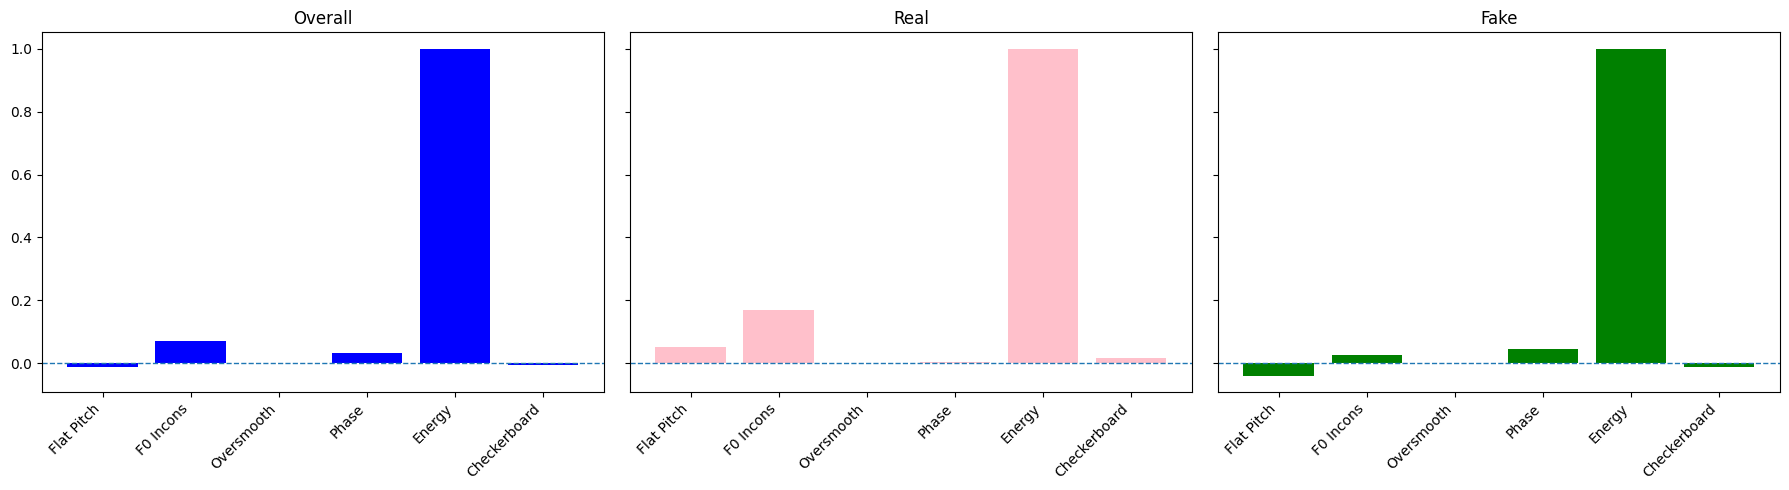

In [42]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_mix/calibration_exp/1a/ALL"
res = analyze_ensemble(rootpath, expert_names=names)

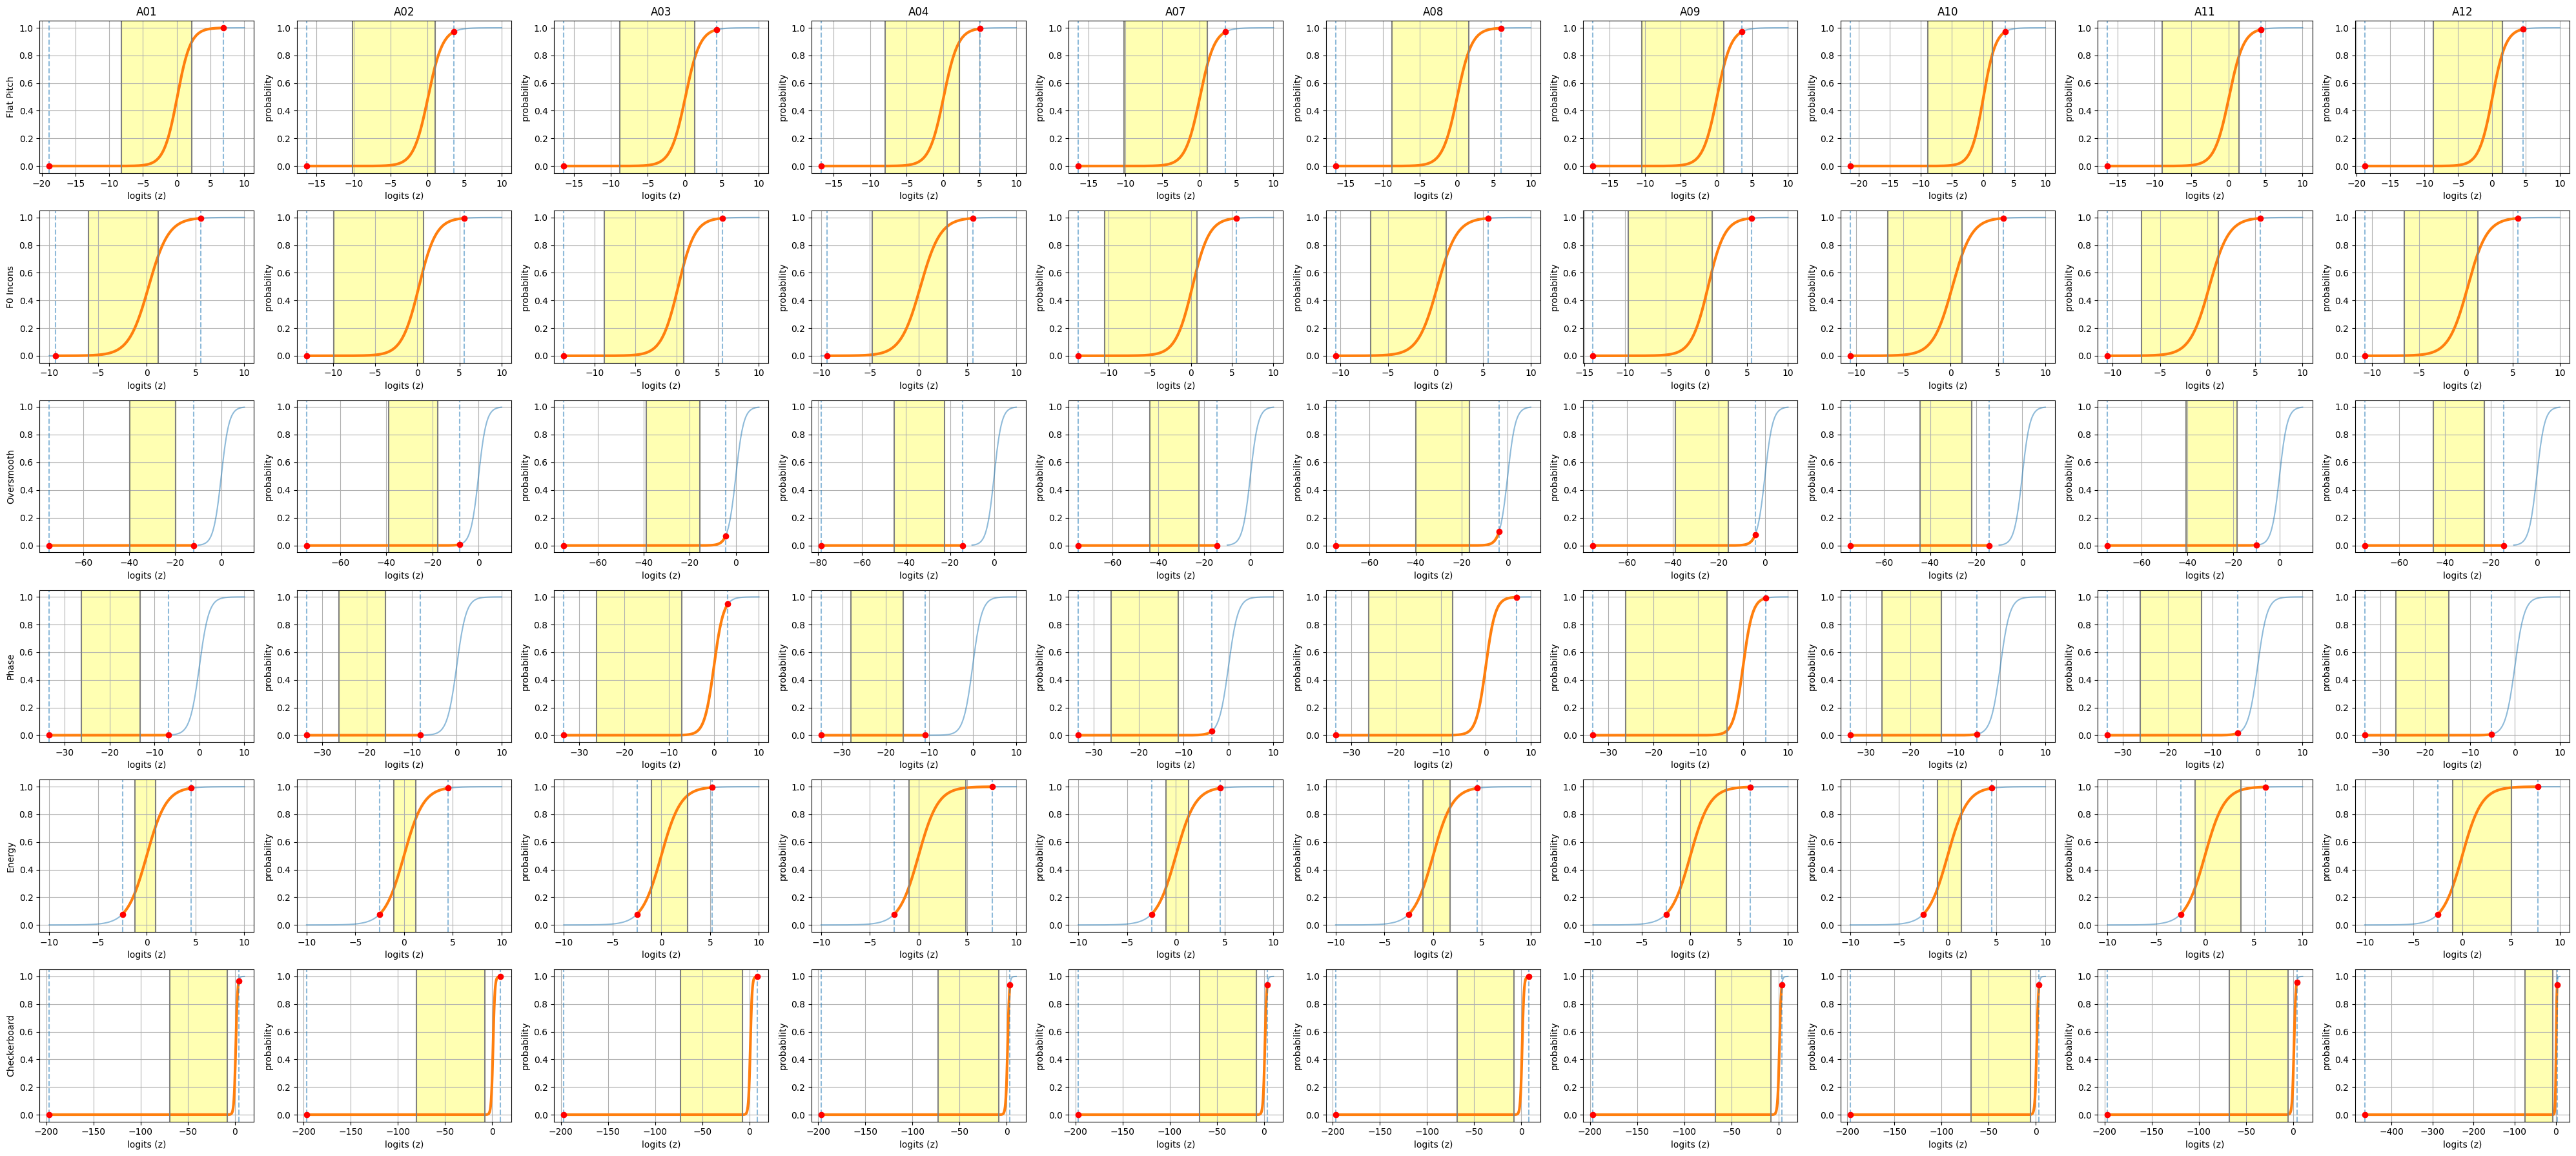

In [44]:
root_base = "/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_mix/calibration_exp/1a"
names = ['Flat Pitch', 'F0 Incons', 'Oversmooth', 'Phase', 'Energy', 'Checkerboard']
plot_platt_all_attacks(root_base, generator_list, names)

Loaded 16634 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 90.87%, EER: 17.06%
Real mean score: -1.2708
Fake mean score: 2.0655


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 43.06%, EER: 55.62%
Real mean score: -0.0047
Fake mean score: -0.0072

--- F0 Incons ---
AUC: 65.50%, EER: 39.25%
Real mean score: -0.1265
Fake mean score: 0.1060

--- Oversmooth ---
AUC: 68.89%, EER: 37.43%
Real mean score: -0.2976
Fake mean score: 0.1762

--- Phase ---
AUC: 83.14%, EER: 25.10%
Real mean score: -0.5486
Fake mean score: 1.0743

--- Energy ---
AUC: 75.83%, EER: 32.22%
Real mean score: -0.3340
Fake mean score: 0.6500

--- Checkerboard ---
AUC: 54.96%, EER: 47.06%
Real mean score: 0.0408
Fake mean score: 0.0663



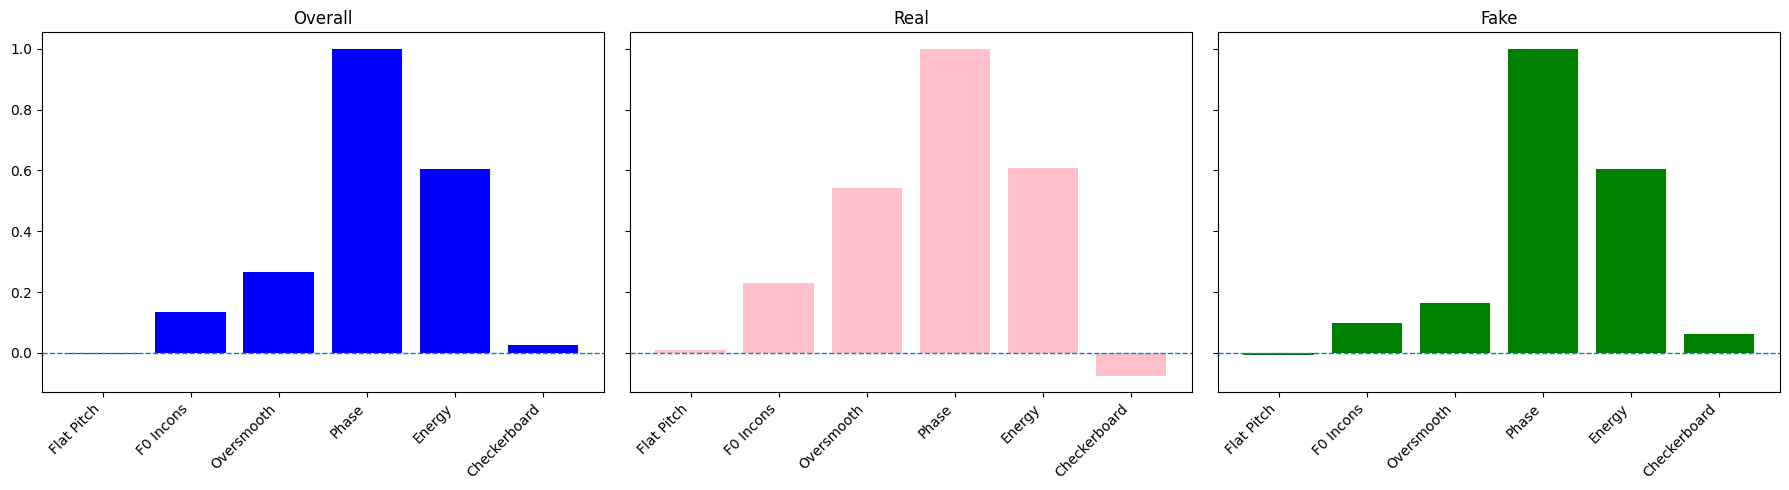

In [24]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_mix/6_experts/ALL"
res = analyze_ensemble(rootpath, expert_names=names)

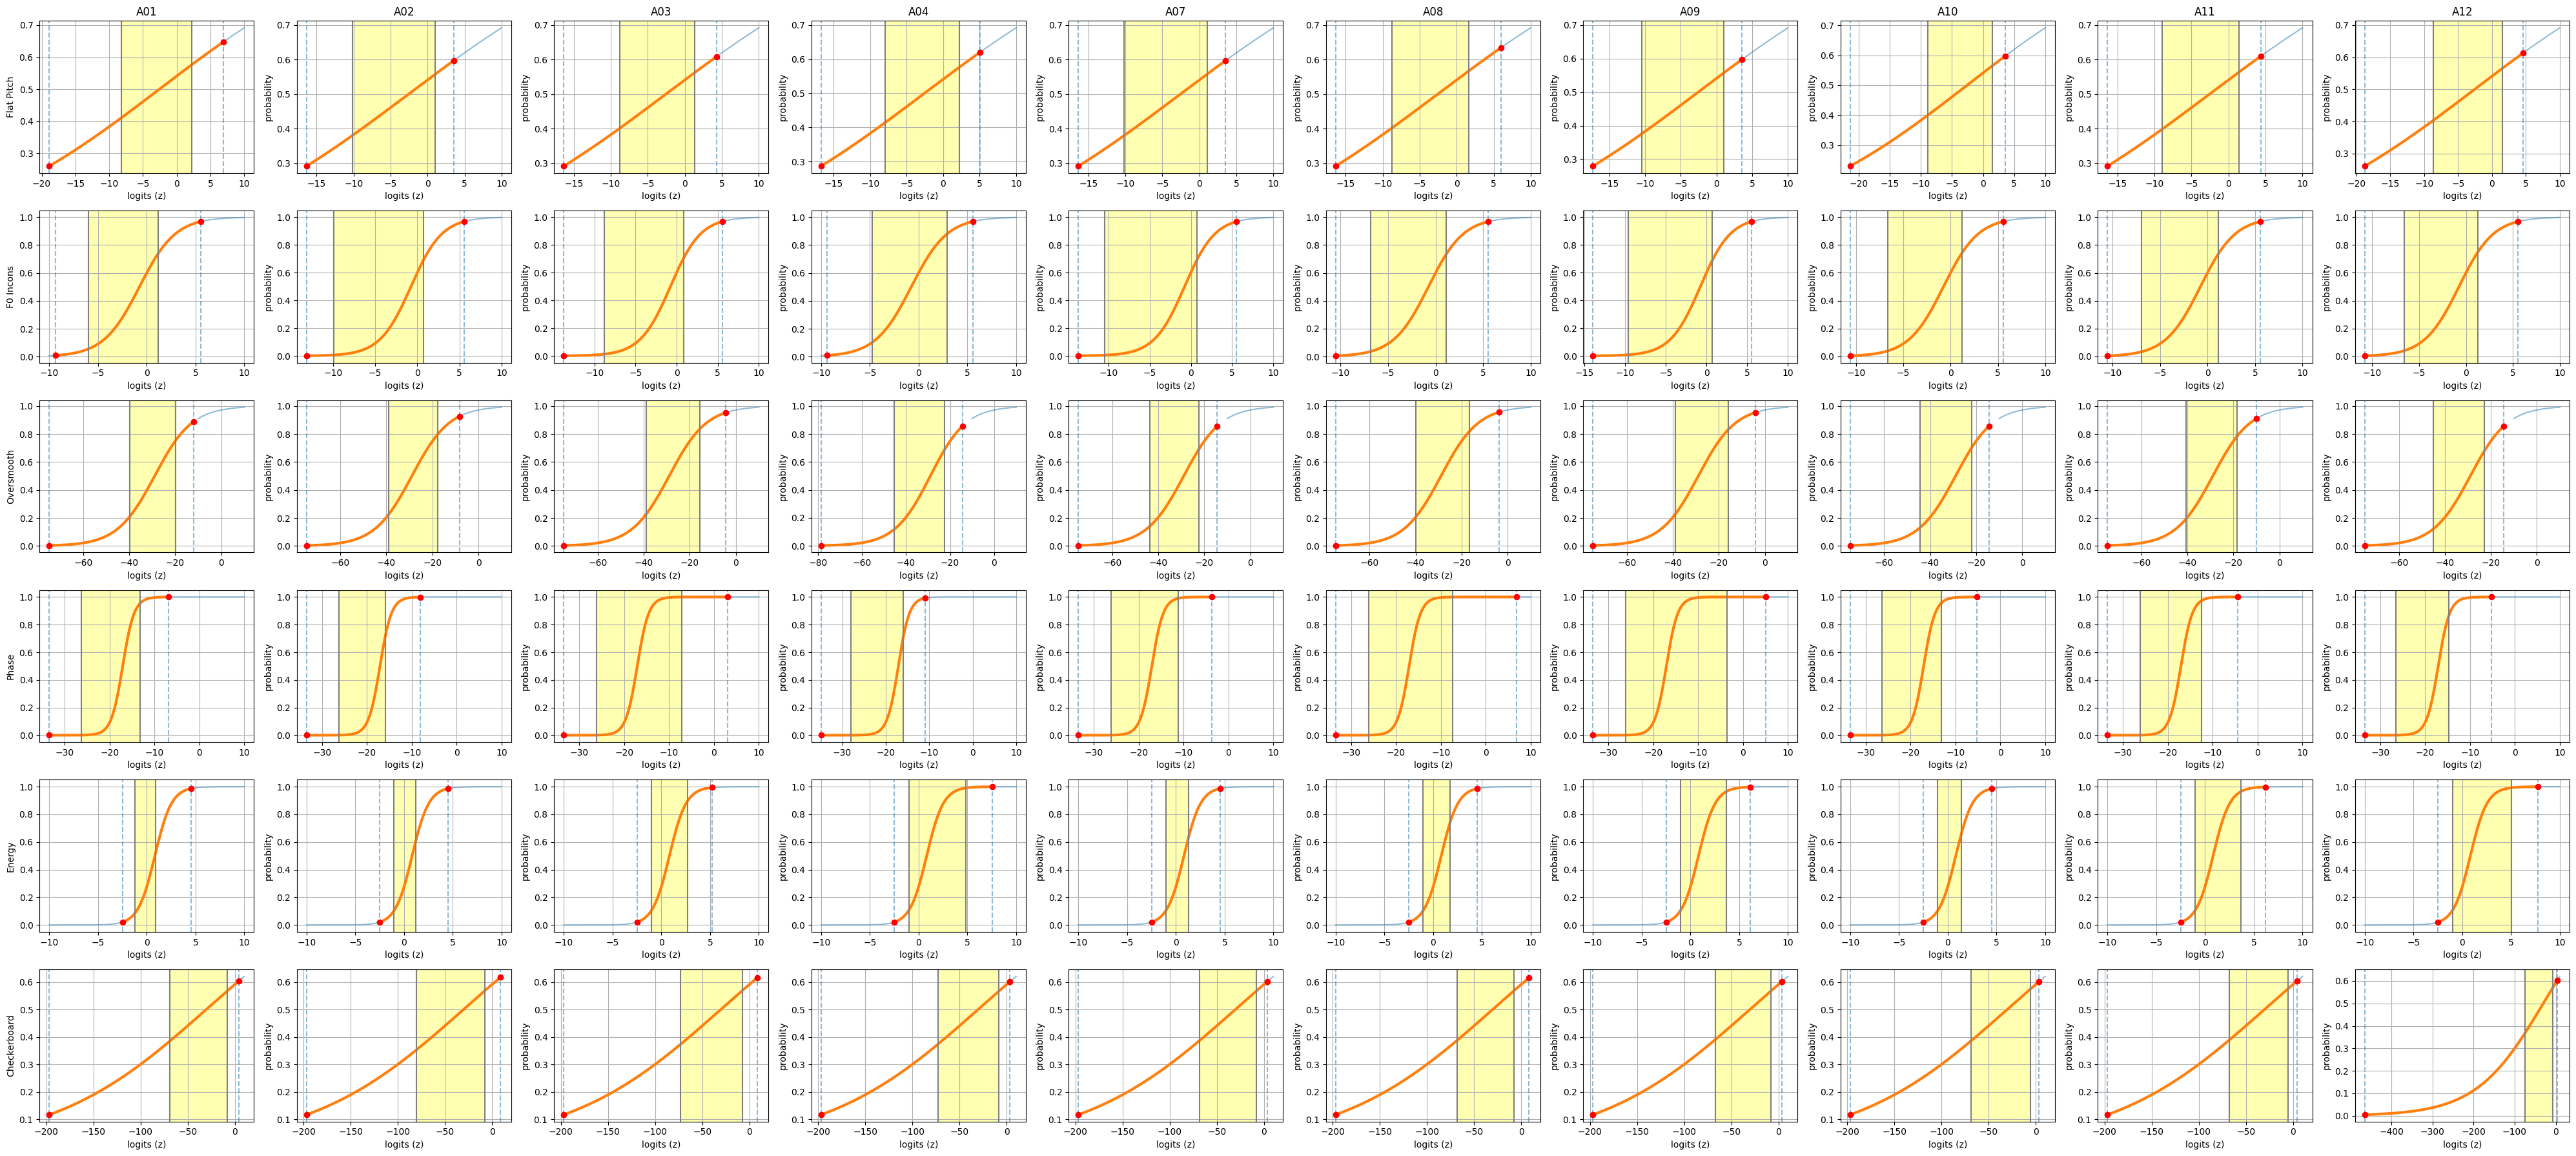

In [11]:
root_base = "/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_mix/6_experts"
names = ['Flat Pitch', 'F0 Incons', 'Oversmooth', 'Phase', 'Energy', 'Checkerboard']
plot_platt_all_attacks(root_base, generator_list, names)


########################################################################################################################
#--------------------------------------------------------- A01 ---------------------------------------------------------#
########################################################################################################################

Loaded 1885 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 77.94%, EER: 28.74%
Real mean score: -1.2535
Fake mean score: 0.0173


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 59.56%, EER: 44.31%
Real mean score: -0.0048
Fake mean score: -0.0002

--- F0 Incons ---
AUC: 53.48%, EER: 47.84%
Real mean score: -0.1210
Fake mean score: -0.0744

--- Oversmooth ---
AUC: 62.83%, EER: 42.74%
Real mean score: -0.3032
Fake mean score: -0.0170

--- Phase ---
AUC: 82.61%, EER: 24.76%
Real mean score: -0.5511
Fake mean score: 0.5266

--- Energy ---
AUC: 36.67%, EER: 58.08%
Real mean score: -0.3129
Fake mean score: -0

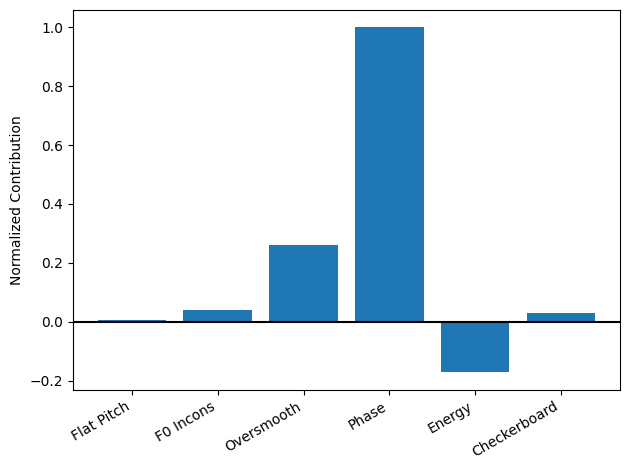


########################################################################################################################
#--------------------------------------------------------- A02 ---------------------------------------------------------#
########################################################################################################################

Loaded 1913 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 85.70%, EER: 21.77%
Real mean score: -1.2535
Fake mean score: 0.1402


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 28.95%, EER: 65.69%
Real mean score: -0.0048
Fake mean score: -0.0136

--- F0 Incons ---
AUC: 77.27%, EER: 29.04%
Real mean score: -0.1210
Fake mean score: 0.3036

--- Oversmooth ---
AUC: 85.77%, EER: 20.91%
Real mean score: -0.3032
Fake mean score: 0.5023

--- Phase ---
AUC: 69.72%, EER: 36.21%
Real mean score: -0.5511
Fake mean score: -0.3077

--- Energy ---
AUC: 54.00%, EER: 46.98%
Real mean score: -0.3129
Fake mean score: -0.

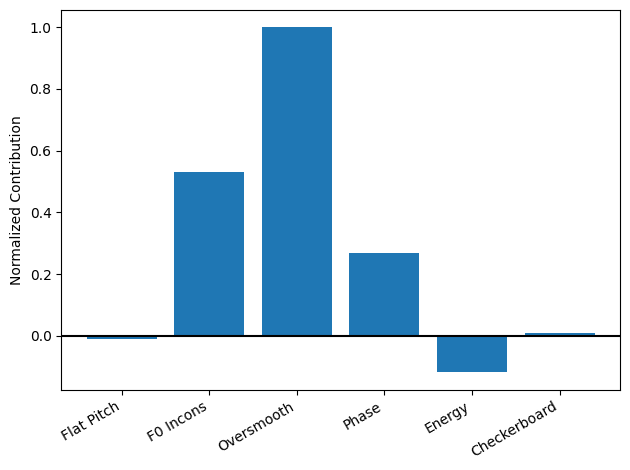


########################################################################################################################
#--------------------------------------------------------- A03 ---------------------------------------------------------#
########################################################################################################################

Loaded 1918 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 99.26%, EER: 4.34%
Real mean score: -1.2535
Fake mean score: 4.4205


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 39.81%, EER: 58.84%
Real mean score: -0.0048
Fake mean score: -0.0081

--- F0 Incons ---
AUC: 71.10%, EER: 34.55%
Real mean score: -0.1210
Fake mean score: 0.2052

--- Oversmooth ---
AUC: 96.30%, EER: 8.59%
Real mean score: -0.3032
Fake mean score: 1.0632

--- Phase ---
AUC: 98.24%, EER: 6.57%
Real mean score: -0.5511
Fake mean score: 2.5256

--- Energy ---
AUC: 84.30%, EER: 22.84%
Real mean score: -0.3129
Fake mean score: 0.5740


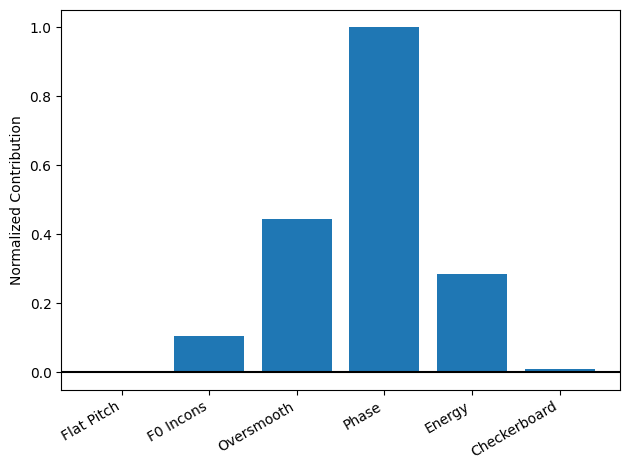


########################################################################################################################
#--------------------------------------------------------- A04 ---------------------------------------------------------#
########################################################################################################################

Loaded 1867 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 87.33%, EER: 21.51%
Real mean score: -1.2535
Fake mean score: 1.2390


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 68.61%, EER: 36.96%
Real mean score: -0.0048
Fake mean score: 0.0027

--- F0 Incons ---
AUC: 60.52%, EER: 42.56%
Real mean score: -0.1210
Fake mean score: -0.0157

--- Oversmooth ---
AUC: 52.11%, EER: 47.71%
Real mean score: -0.3032
Fake mean score: -0.3039

--- Phase ---
AUC: 52.86%, EER: 46.86%
Real mean score: -0.5511
Fake mean score: -0.4126

--- Energy ---
AUC: 87.75%, EER: 23.49%
Real mean score: -0.3129
Fake mean score: 1.

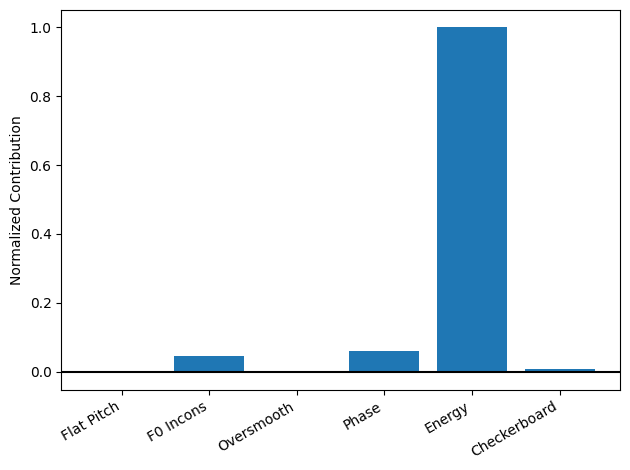


########################################################################################################################
#--------------------------------------------------------- A07 ---------------------------------------------------------#
########################################################################################################################

Loaded 1927 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 88.31%, EER: 20.32%
Real mean score: -1.2535
Fake mean score: 0.9663


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 27.30%, EER: 67.78%
Real mean score: -0.0048
Fake mean score: -0.0142

--- F0 Incons ---
AUC: 80.94%, EER: 26.19%
Real mean score: -0.1210
Fake mean score: 0.3597

--- Oversmooth ---
AUC: 50.33%, EER: 48.92%
Real mean score: -0.3032
Fake mean score: -0.3208

--- Phase ---
AUC: 89.53%, EER: 18.62%
Real mean score: -0.5511
Fake mean score: 1.2203

--- Energy ---
AUC: 62.77%, EER: 40.04%
Real mean score: -0.3129
Fake mean score: -0.

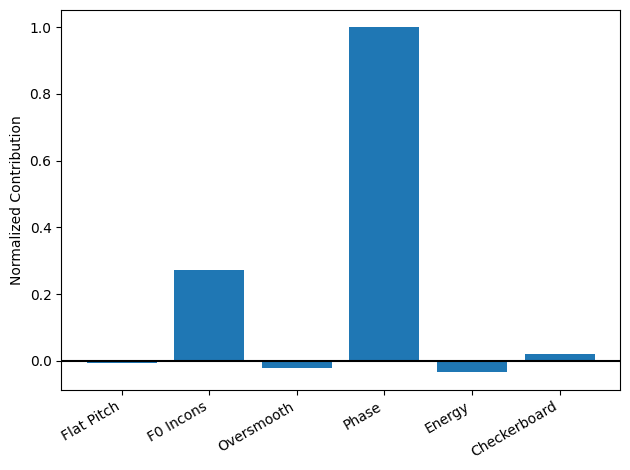


########################################################################################################################
#--------------------------------------------------------- A08 ---------------------------------------------------------#
########################################################################################################################

Loaded 1920 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 97.49%, EER: 7.66%
Real mean score: -1.2535
Fake mean score: 2.6897


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 49.93%, EER: 51.08%
Real mean score: -0.0048
Fake mean score: -0.0045

--- F0 Incons ---
AUC: 61.00%, EER: 42.56%
Real mean score: -0.1210
Fake mean score: 0.0197

--- Oversmooth ---
AUC: 78.22%, EER: 29.09%
Real mean score: -0.3032
Fake mean score: 0.4154

--- Phase ---
AUC: 96.61%, EER: 10.02%
Real mean score: -0.5511
Fake mean score: 2.2967

--- Energy ---
AUC: 72.15%, EER: 31.96%
Real mean score: -0.3129
Fake mean score: -0.10

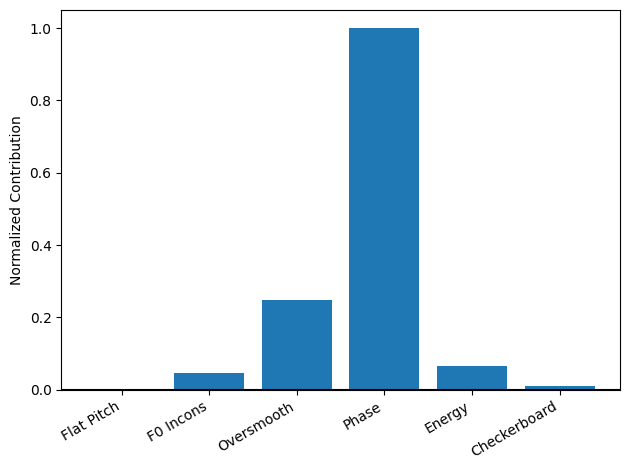


########################################################################################################################
#--------------------------------------------------------- A09 ---------------------------------------------------------#
########################################################################################################################

Loaded 1926 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 99.97%, EER: 1.30%
Real mean score: -1.2535
Fake mean score: 5.5978


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 25.98%, EER: 68.64%
Real mean score: -0.0048
Fake mean score: -0.0151

--- F0 Incons ---
AUC: 80.90%, EER: 25.55%
Real mean score: -0.1210
Fake mean score: 0.3510

--- Oversmooth ---
AUC: 89.32%, EER: 16.43%
Real mean score: -0.3032
Fake mean score: 0.8111

--- Phase ---
AUC: 99.76%, EER: 2.37%
Real mean score: -0.5511
Fake mean score: 3.0224

--- Energy ---
AUC: 93.22%, EER: 14.66%
Real mean score: -0.3129
Fake mean score: 1.3509

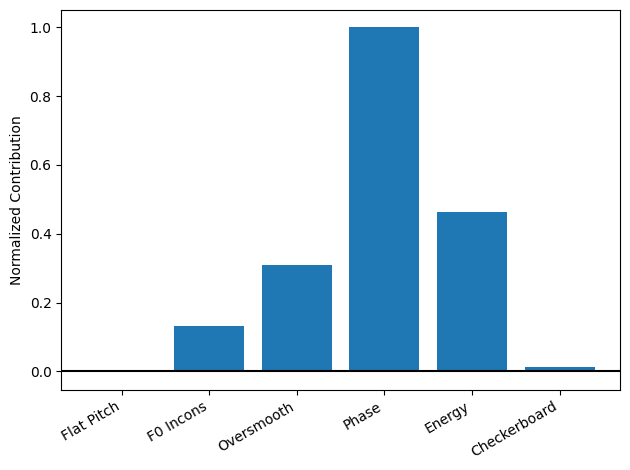


########################################################################################################################
#--------------------------------------------------------- A10 ---------------------------------------------------------#
########################################################################################################################

Loaded 1885 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 75.18%, EER: 31.45%
Real mean score: -1.2535
Fake mean score: -0.0383


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 45.29%, EER: 54.20%
Real mean score: -0.0048
Fake mean score: -0.0064

--- F0 Incons ---
AUC: 56.77%, EER: 45.66%
Real mean score: -0.1210
Fake mean score: -0.0309

--- Oversmooth ---
AUC: 51.76%, EER: 48.38%
Real mean score: -0.3032
Fake mean score: -0.2769

--- Phase ---
AUC: 80.22%, EER: 26.62%
Real mean score: -0.5511
Fake mean score: 0.5263

--- Energy ---
AUC: 64.25%, EER: 38.98%
Real mean score: -0.3129
Fake mean score: -

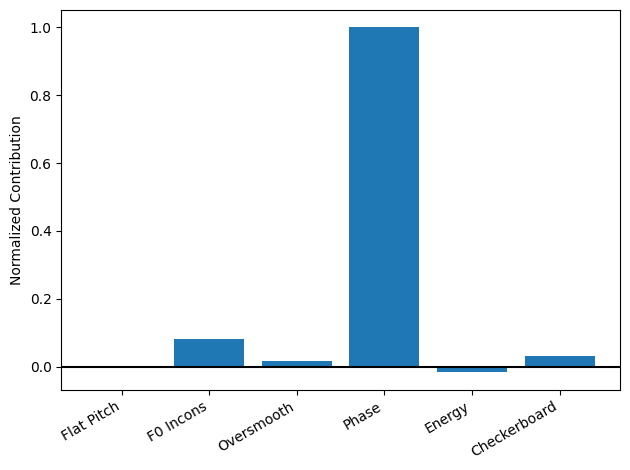


########################################################################################################################
#--------------------------------------------------------- A11 ---------------------------------------------------------#
########################################################################################################################

Loaded 1889 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 98.03%, EER: 7.18%
Real mean score: -1.2535
Fake mean score: 3.0919


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 45.48%, EER: 53.56%
Real mean score: -0.0048
Fake mean score: -0.0062

--- F0 Incons ---
AUC: 58.87%, EER: 44.61%
Real mean score: -0.1210
Fake mean score: 0.0011

--- Oversmooth ---
AUC: 68.98%, EER: 37.07%
Real mean score: -0.3032
Fake mean score: 0.1188

--- Phase ---
AUC: 89.65%, EER: 18.52%
Real mean score: -0.5511
Fake mean score: 1.0113

--- Energy ---
AUC: 96.18%, EER: 9.57%
Real mean score: -0.3129
Fake mean score: 1.8901

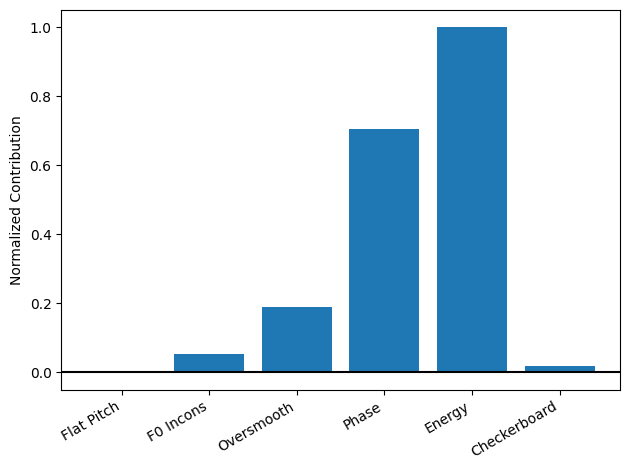


########################################################################################################################
#--------------------------------------------------------- A12 ---------------------------------------------------------#
########################################################################################################################

Loaded 1863 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 95.29%, EER: 10.05%
Real mean score: -1.2535
Fake mean score: 2.1051


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 48.64%, EER: 52.05%
Real mean score: -0.0048
Fake mean score: -0.0049

--- F0 Incons ---
AUC: 54.37%, EER: 48.49%
Real mean score: -0.1210
Fake mean score: -0.0468

--- Oversmooth ---
AUC: 50.74%, EER: 47.91%
Real mean score: -0.3032
Fake mean score: -0.3364

--- Phase ---
AUC: 71.81%, EER: 33.48%
Real mean score: -0.5511
Fake mean score: 0.0319

--- Energy ---
AUC: 97.43%, EER: 8.62%
Real mean score: -0.3129
Fake mean score: 2.4

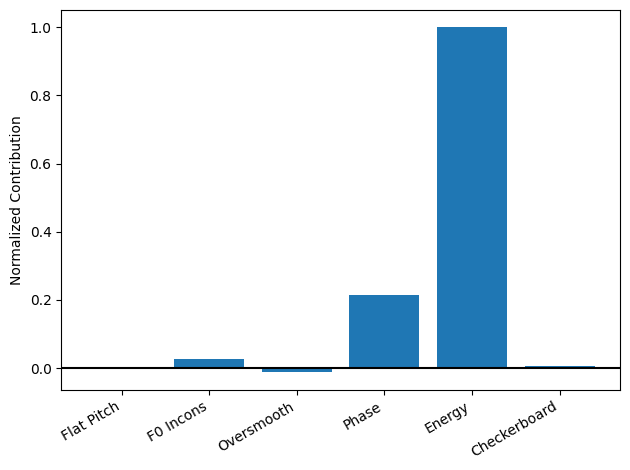

In [12]:
for a in generator_list:
    print(f"\n{'#'*120}")
    print(f"#{'-'*57} {a} {'-'*57}#")
    print(f"{'#'*120}\n")
    
    path = f"/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_mix/6_experts/{a}"
    res = analyze_ensemble(path, expert_names=names)

## Test set: ASVspoof 5 

In [13]:
generator_list = ['A01', 'A02', 'A03', 'A04', 'A05', 'A06', 'A07', 'A08', 'A09', 'A10', 'A11', 'A12', 'A14', 'A17', 'A19', 'A21', 'A22', 'A28', 'A29']    

Loaded 36409 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 69.35%, EER: 35.64%
Real mean score: -0.7181
Fake mean score: 0.1299


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 54.49%, EER: 46.53%
Real mean score: 0.0314
Fake mean score: 0.0519

--- F0 Incons ---
AUC: 51.12%, EER: 49.07%
Real mean score: 0.0263
Fake mean score: 0.0309

--- Oversmooth ---
AUC: 60.57%, EER: 40.94%
Real mean score: -0.4096
Fake mean score: -0.0631

--- Phase ---
AUC: 55.77%, EER: 45.88%
Real mean score: -0.0771
Fake mean score: 0.0143

--- Energy ---
AUC: 55.23%, EER: 45.14%
Real mean score: -0.0334
Fake mean score: -0.0098

--- Checkerboard ---
AUC: 68.10%, EER: 36.48%
Real mean score: -0.2558
Fake mean score: 0.1058



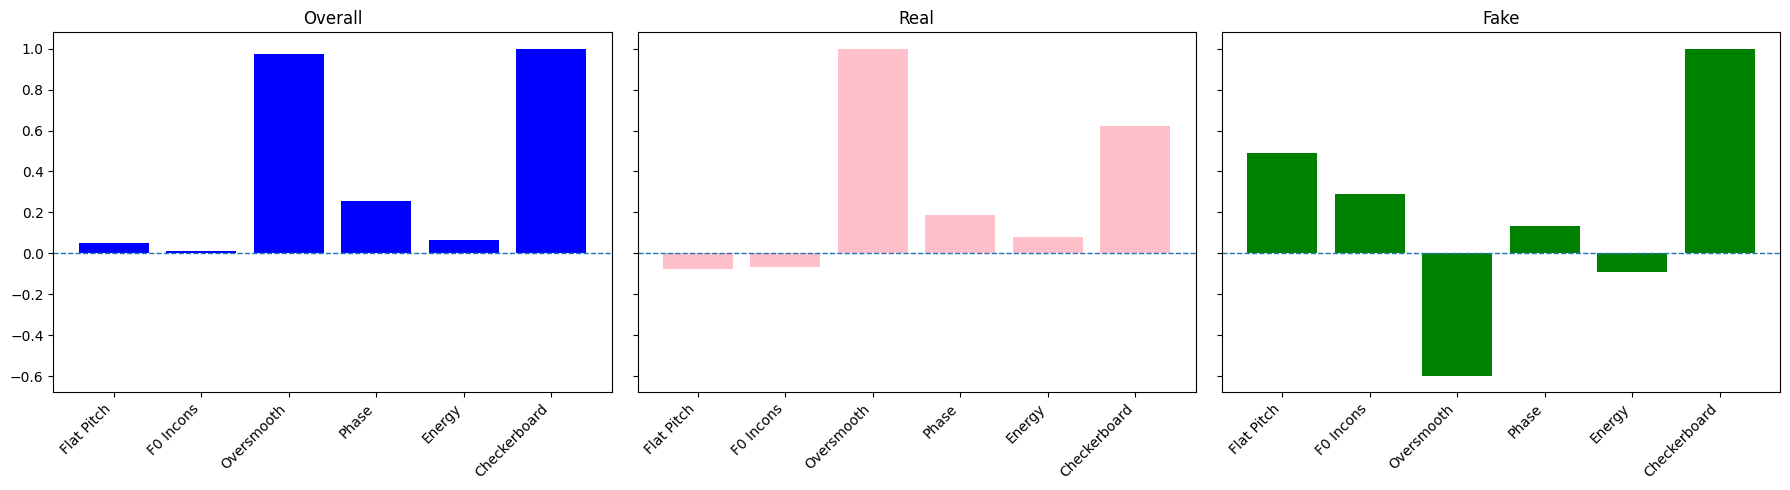

In [46]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv5/experts_trained_on_mix/6_experts/ALL"
res = analyze_ensemble(rootpath, expert_names=names)

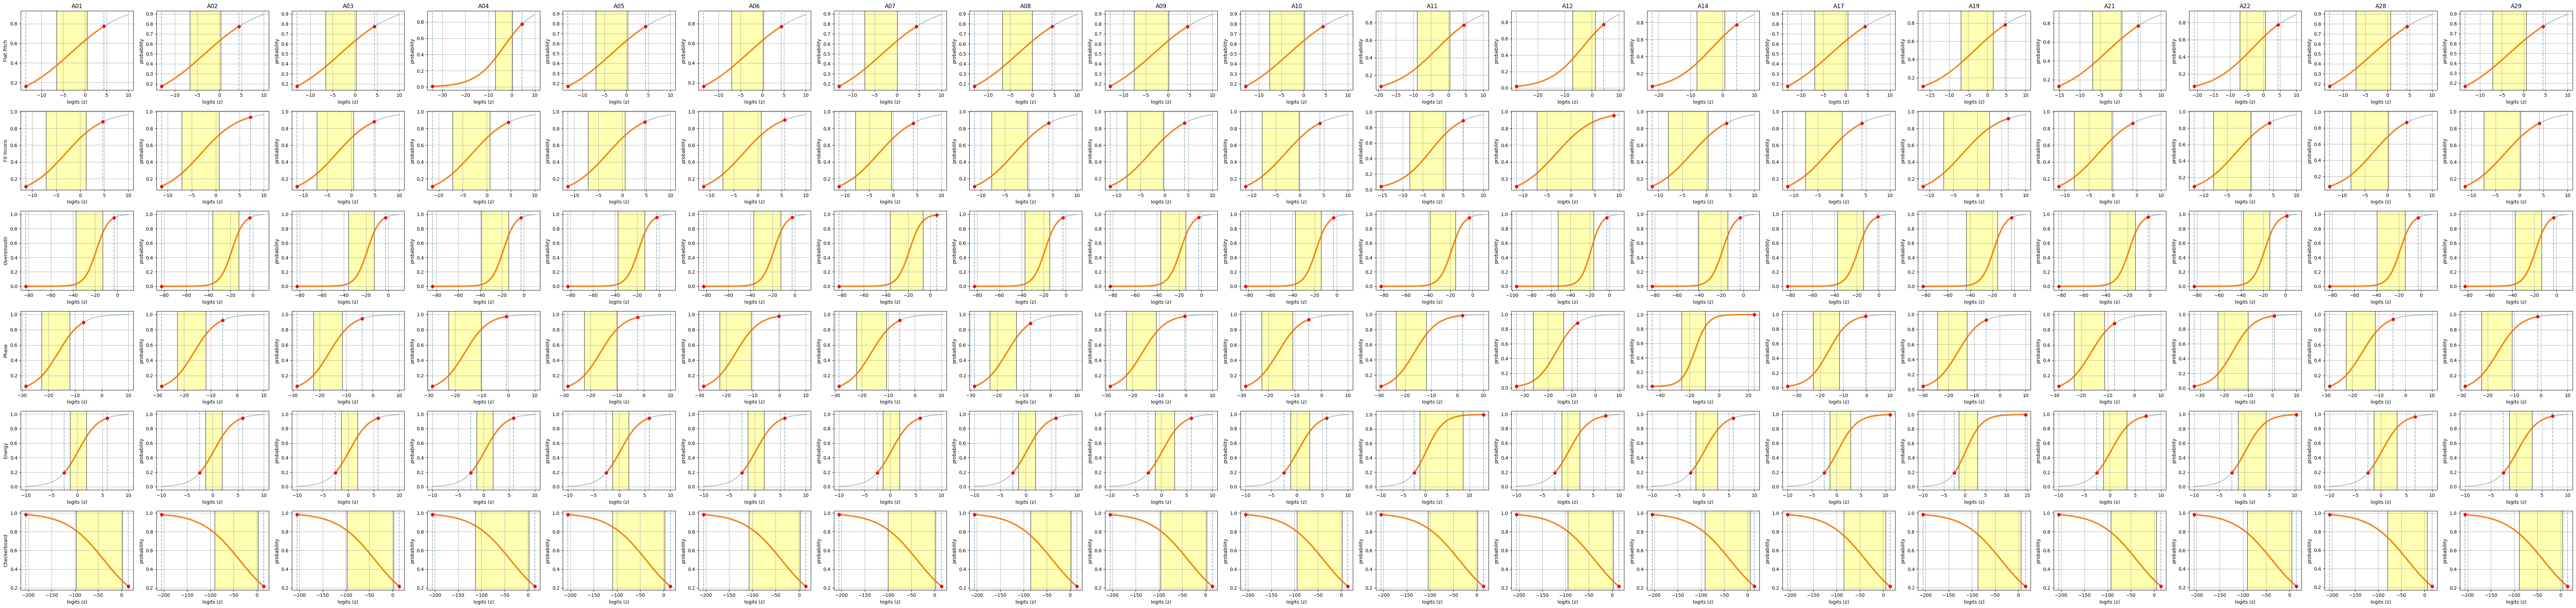

In [35]:
root_base = "/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv5/experts_trained_on_mix/6_experts"
names = ['Flat Pitch', 'F0 Incons', 'Oversmooth', 'Phase', 'Energy', 'Checkerboard']
plot_platt_all_attacks(root_base, generator_list, names)

### Same calibration data as ASV19

Loaded 36409 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 56.82%, EER: 44.81%
Real mean score: 1.1474
Fake mean score: 1.6149


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 46.59%, EER: 53.02%
Real mean score: -0.0059
Fake mean score: -0.0067

--- F0 Incons ---
AUC: 46.63%, EER: 52.11%
Real mean score: 0.0986
Fake mean score: 0.0511

--- Oversmooth ---
AUC: 61.37%, EER: 40.92%
Real mean score: 0.3815
Fake mean score: 0.7268

--- Phase ---
AUC: 55.77%, EER: 45.88%
Real mean score: 0.6185
Fake mean score: 0.9231

--- Energy ---
AUC: 46.86%, EER: 54.20%
Real mean score: 0.0114
Fake mean score: -0.0793

--- Checkerboard ---
AUC: 33.36%, EER: 63.52%
Real mean score: 0.0432
Fake mean score: -0.0000



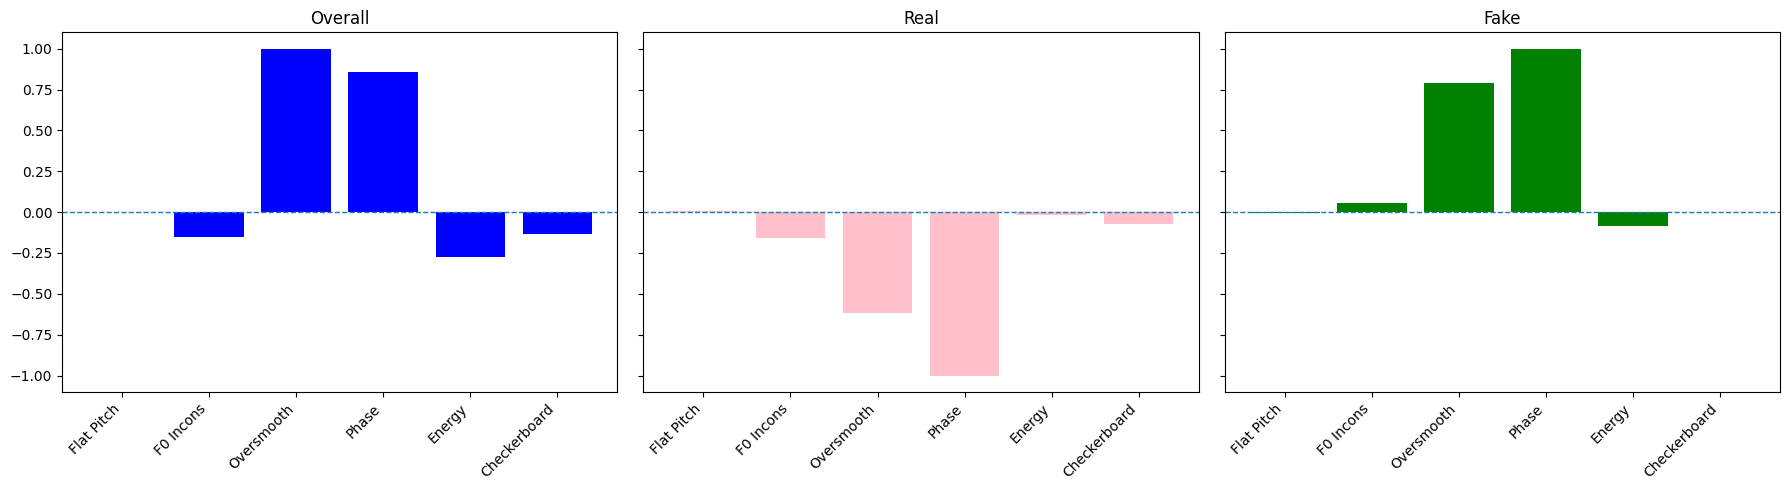

In [47]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv5/experts_trained_on_mix/calibration_exp/trial/ALL"
res = analyze_ensemble(rootpath, expert_names=names)

# Train set: ASVspoof 2019 only 
## Test set: ASVspoof 2019


In [26]:
names = ['Flat Pitch', 'F0 Incons', 'Oversmooth', 'Phase', 'Energy', 'Checkerboard']
generator_list = ['A01', 'A02', 'A03', 'A04', 'A07', 'A08', 'A09', 'A10', 'A11', 'A12']

Loaded 19171 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 91.13%, EER: 17.17%
Real mean score: -1.3920
Fake mean score: 3.1462


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 42.34%, EER: 55.89%
Real mean score: 0.0065
Fake mean score: 0.0052

--- F0 Incons ---
AUC: 67.02%, EER: 38.15%
Real mean score: -0.1098
Fake mean score: 0.1339

--- Oversmooth ---
AUC: 70.95%, EER: 35.27%
Real mean score: -0.3712
Fake mean score: 0.4805

--- Phase ---
AUC: 76.80%, EER: 30.35%
Real mean score: -0.2720
Fake mean score: 0.6055

--- Energy ---
AUC: 81.88%, EER: 28.08%
Real mean score: -0.6559
Fake mean score: 1.7730

--- Checkerboard ---
AUC: 61.75%, EER: 41.69%
Real mean score: 0.0104
Fake mean score: 0.1481



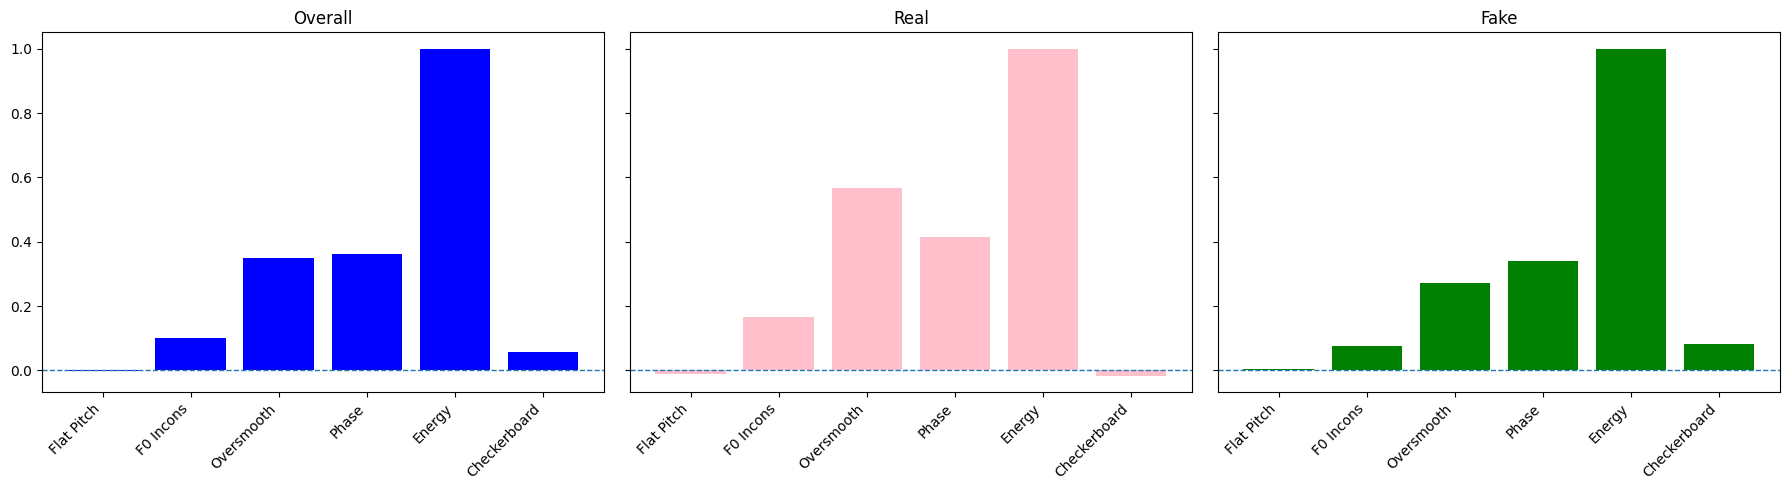

In [37]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_asv19/6_experts/ALL"
res = analyze_ensemble(rootpath, expert_names=names)

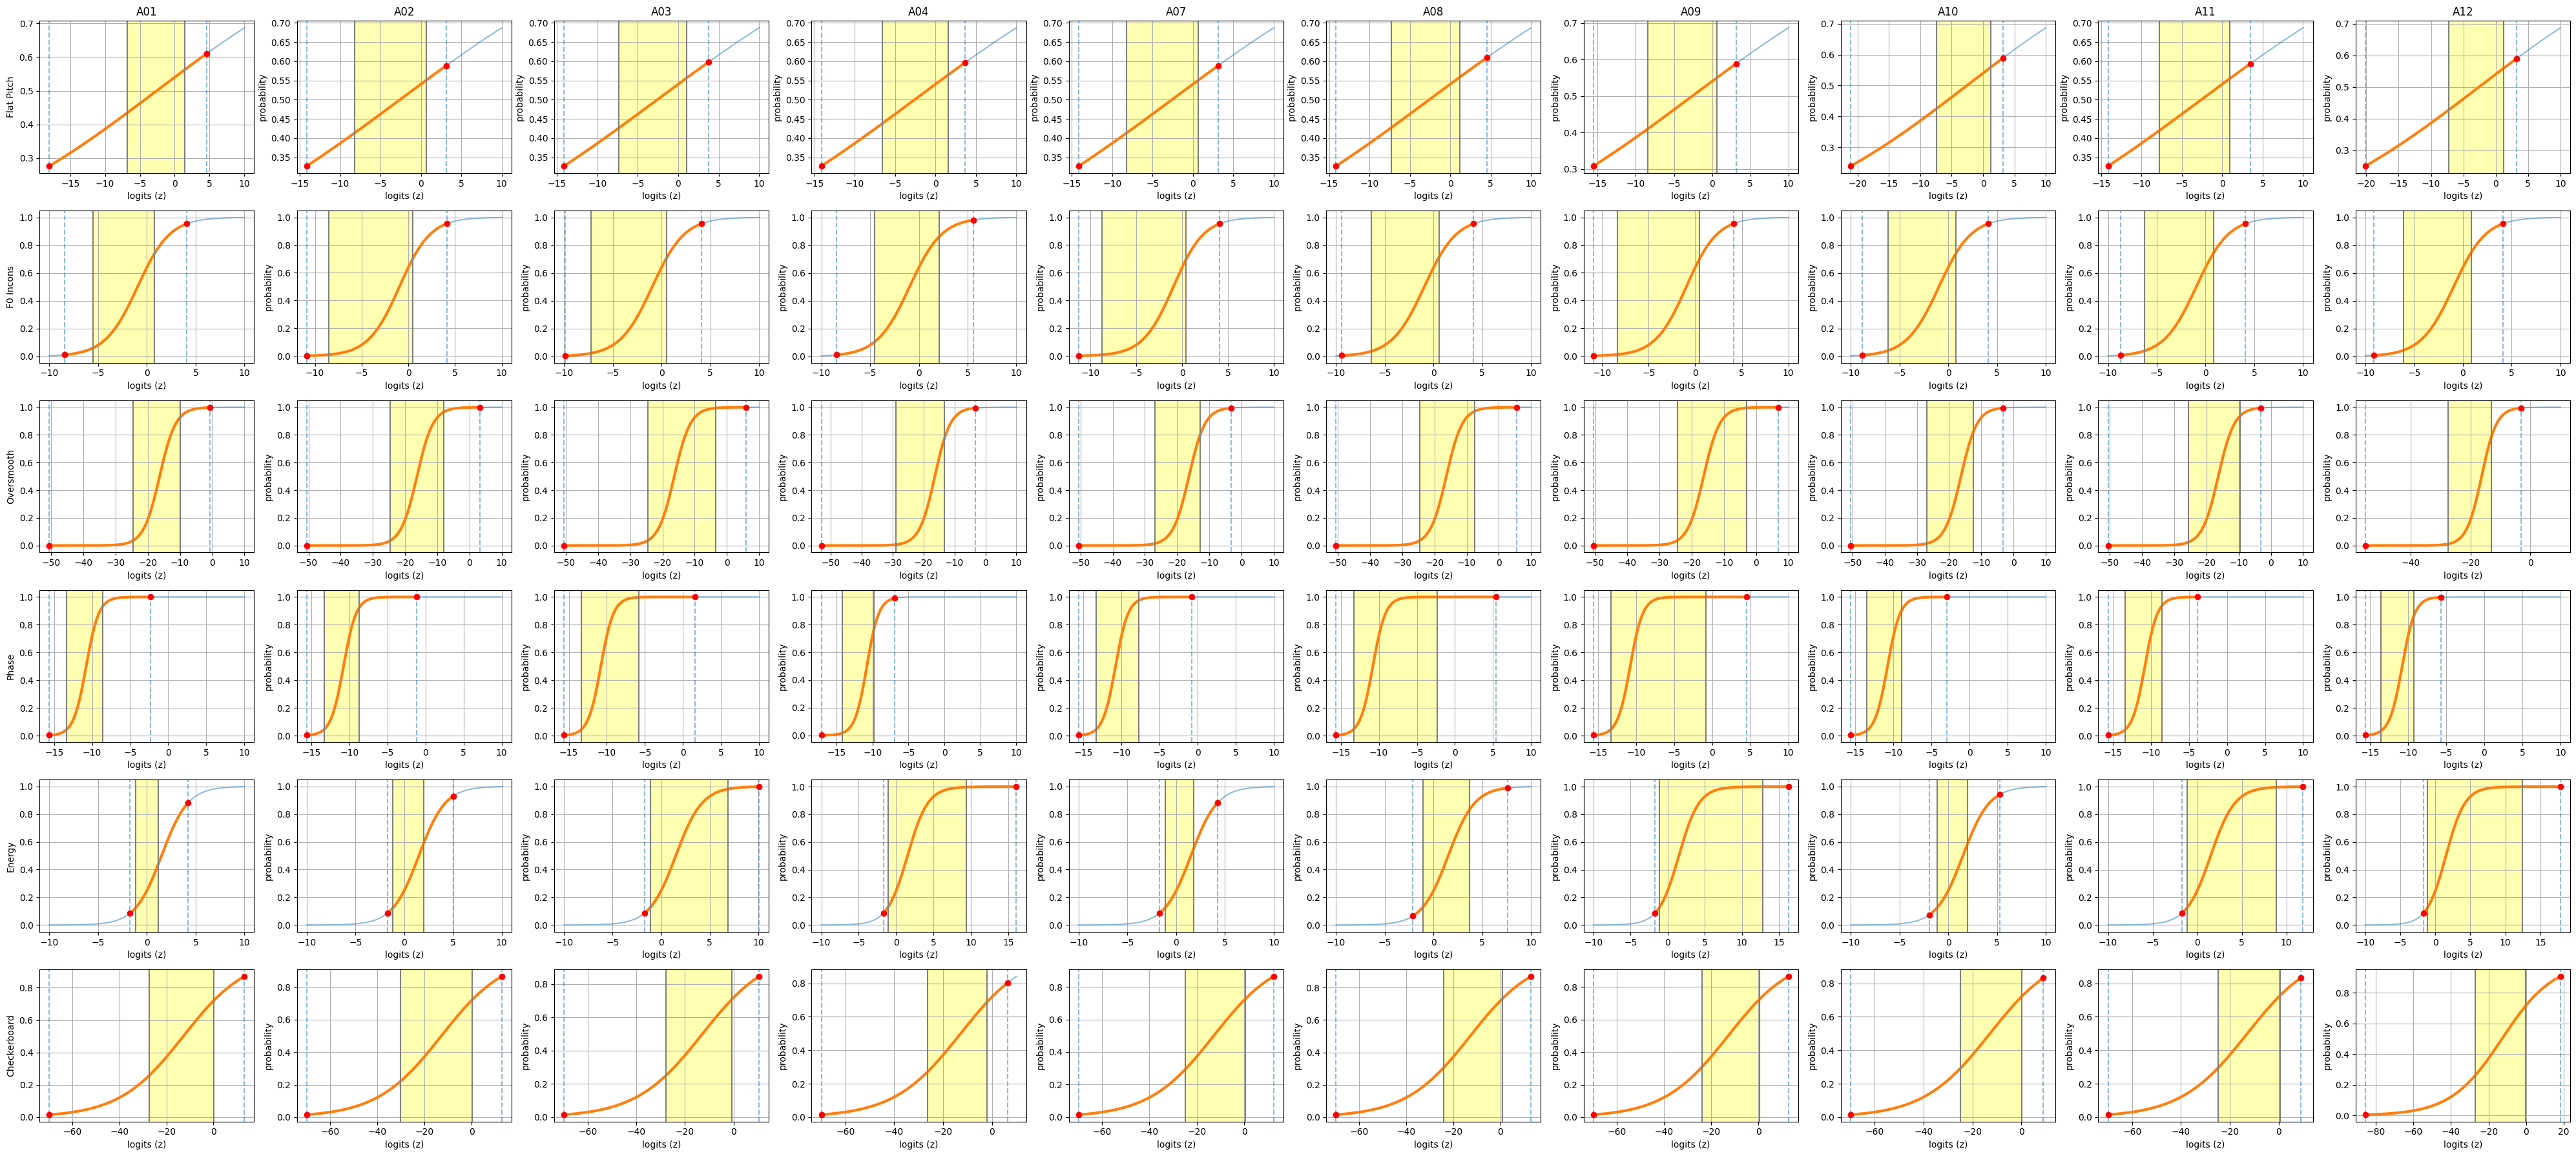

In [17]:
root_base = "/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_asv19/6_experts"
names = ['Flat Pitch', 'F0 Incons', 'Oversmooth', 'Phase', 'Energy', 'Checkerboard']
plot_platt_all_attacks(root_base, generator_list, names)



########################################################################################################################
#--------------------------------------------------------- A01 ---------------------------------------------------------#
########################################################################################################################

Loaded 1898 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 80.24%, EER: 26.14%
Real mean score: -1.3451
Fake mean score: 0.1070


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 57.62%, EER: 44.21%
Real mean score: 0.0069
Fake mean score: 0.0082

--- F0 Incons ---
AUC: 56.73%, EER: 44.83%
Real mean score: -0.0997
Fake mean score: -0.0193

--- Oversmooth ---
AUC: 77.39%, EER: 26.67%
Real mean score: -0.3768
Fake mean score: 0.4747

--- Phase ---
AUC: 71.72%, EER: 33.44%
Real mean score: -0.2523
Fake mean score: 0.2608

--- Energy ---
AUC: 52.14%, EER: 47.82%
Real mean score: -0.6369
Fake mean score: -0.71

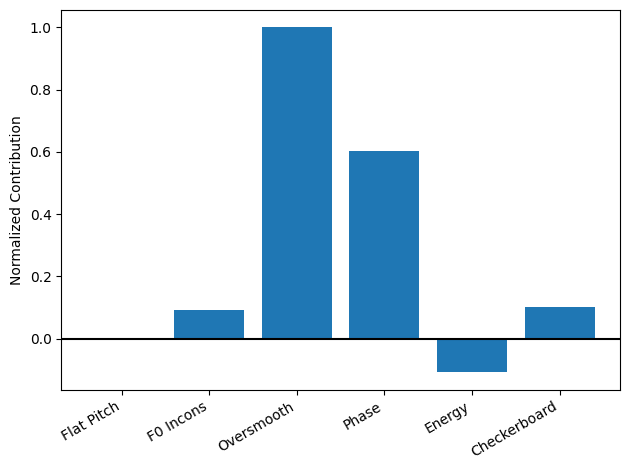


########################################################################################################################
#--------------------------------------------------------- A02 ---------------------------------------------------------#
########################################################################################################################

Loaded 1926 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 91.75%, EER: 15.52%
Real mean score: -1.3451
Fake mean score: 1.2241


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 30.83%, EER: 63.45%
Real mean score: 0.0069
Fake mean score: 0.0029

--- F0 Incons ---
AUC: 79.29%, EER: 27.51%
Real mean score: -0.0997
Fake mean score: 0.3456

--- Oversmooth ---
AUC: 89.88%, EER: 16.37%
Real mean score: -0.3768
Fake mean score: 1.1796

--- Phase ---
AUC: 70.73%, EER: 34.75%
Real mean score: -0.2523
Fake mean score: 0.2211

--- Energy ---
AUC: 59.88%, EER: 42.44%
Real mean score: -0.6369
Fake mean score: -0.566

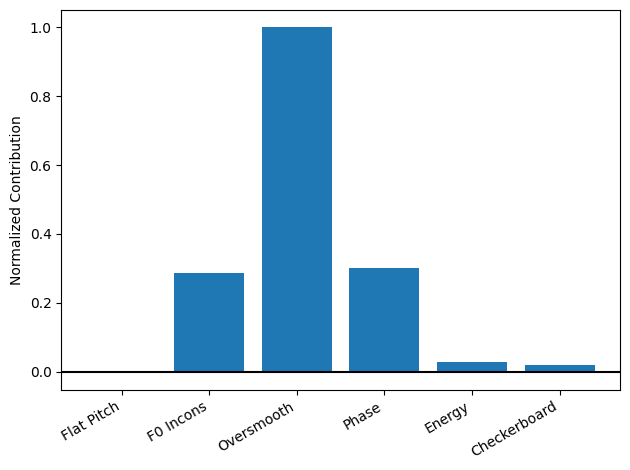


########################################################################################################################
#--------------------------------------------------------- A03 ---------------------------------------------------------#
########################################################################################################################

Loaded 1931 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 99.71%, EER: 2.66%
Real mean score: -1.3451
Fake mean score: 6.1321


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 39.10%, EER: 58.45%
Real mean score: 0.0069
Fake mean score: 0.0051

--- F0 Incons ---
AUC: 72.30%, EER: 33.26%
Real mean score: -0.0997
Fake mean score: 0.2286

--- Oversmooth ---
AUC: 96.18%, EER: 10.10%
Real mean score: -0.3768
Fake mean score: 1.6420

--- Phase ---
AUC: 87.60%, EER: 20.00%
Real mean score: -0.2523
Fake mean score: 1.0238

--- Energy ---
AUC: 97.34%, EER: 7.17%
Real mean score: -0.6369
Fake mean score: 3.1456



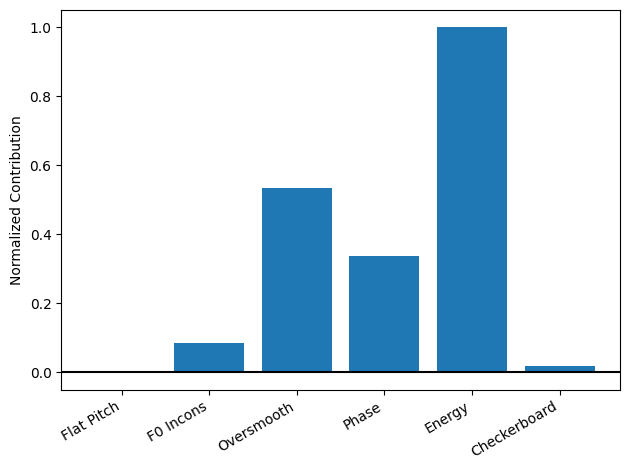


########################################################################################################################
#--------------------------------------------------------- A04 ---------------------------------------------------------#
########################################################################################################################

Loaded 1880 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 82.66%, EER: 26.46%
Real mean score: -1.3451
Fake mean score: 2.2354


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 56.84%, EER: 45.48%
Real mean score: 0.0069
Fake mean score: 0.0083

--- F0 Incons ---
AUC: 53.75%, EER: 44.41%
Real mean score: -0.0997
Fake mean score: -0.0900

--- Oversmooth ---
AUC: 45.75%, EER: 51.54%
Real mean score: -0.3767
Fake mean score: -0.5190

--- Phase ---
AUC: 46.05%, EER: 55.26%
Real mean score: -0.2523
Fake mean score: -0.3334

--- Energy ---
AUC: 89.35%, EER: 22.00%
Real mean score: -0.6369
Fake mean score: 3.1

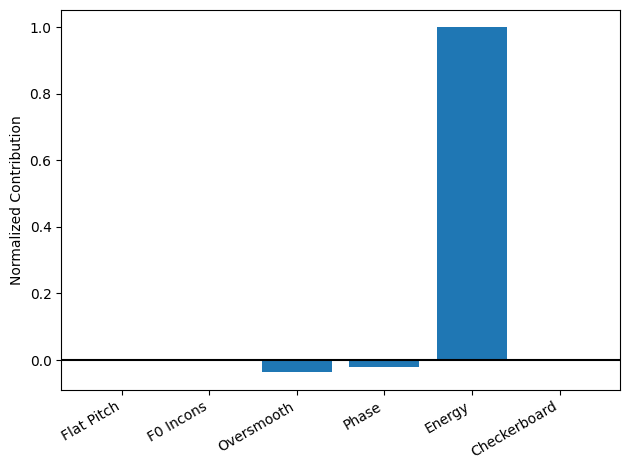


########################################################################################################################
#--------------------------------------------------------- A07 ---------------------------------------------------------#
########################################################################################################################

Loaded 1940 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 84.87%, EER: 23.12%
Real mean score: -1.3451
Fake mean score: 0.2432


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 28.99%, EER: 64.61%
Real mean score: 0.0069
Fake mean score: 0.0027

--- F0 Incons ---
AUC: 82.56%, EER: 23.82%
Real mean score: -0.0997
Fake mean score: 0.3940

--- Oversmooth ---
AUC: 46.19%, EER: 53.13%
Real mean score: -0.3768
Fake mean score: -0.4666

--- Phase ---
AUC: 83.41%, EER: 24.02%
Real mean score: -0.2523
Fake mean score: 0.6903

--- Energy ---
AUC: 66.95%, EER: 37.30%
Real mean score: -0.6369
Fake mean score: -0.62

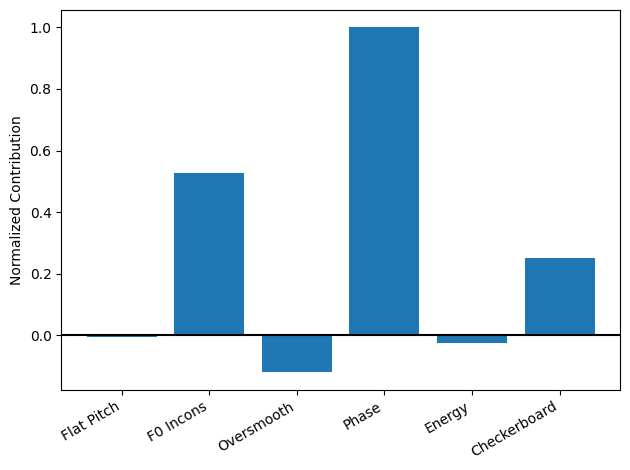


########################################################################################################################
#--------------------------------------------------------- A08 ---------------------------------------------------------#
########################################################################################################################

Loaded 1933 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 98.22%, EER: 6.65%
Real mean score: -1.3451
Fake mean score: 3.4048


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 47.09%, EER: 51.51%
Real mean score: 0.0069
Fake mean score: 0.0064

--- F0 Incons ---
AUC: 65.28%, EER: 39.53%
Real mean score: -0.0997
Fake mean score: 0.1008

--- Oversmooth ---
AUC: 81.78%, EER: 23.59%
Real mean score: -0.3768
Fake mean score: 0.9492

--- Phase ---
AUC: 97.08%, EER: 8.82%
Real mean score: -0.2523
Fake mean score: 1.6969

--- Energy ---
AUC: 83.24%, EER: 26.41%
Real mean score: -0.6369
Fake mean score: 0.4625



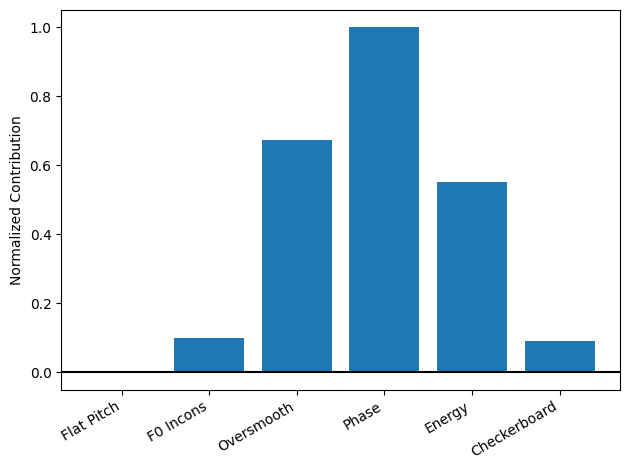


########################################################################################################################
#--------------------------------------------------------- A09 ---------------------------------------------------------#
########################################################################################################################

Loaded 1939 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 100.00%, EER: 0.10%
Real mean score: -1.3451
Fake mean score: 8.5610


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 26.06%, EER: 67.94%
Real mean score: 0.0069
Fake mean score: 0.0018

--- F0 Incons ---
AUC: 82.27%, EER: 25.65%
Real mean score: -0.0997
Fake mean score: 0.3759

--- Oversmooth ---
AUC: 95.39%, EER: 11.12%
Real mean score: -0.3768
Fake mean score: 1.6841

--- Phase ---
AUC: 98.97%, EER: 4.71%
Real mean score: -0.2523
Fake mean score: 1.9038

--- Energy ---
AUC: 99.59%, EER: 3.01%
Real mean score: -0.6369
Fake mean score: 4.3772



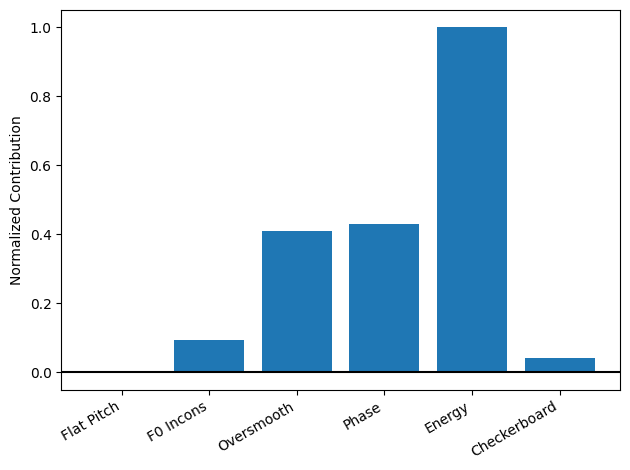


########################################################################################################################
#--------------------------------------------------------- A10 ---------------------------------------------------------#
########################################################################################################################

Loaded 1898 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 69.28%, EER: 36.13%
Real mean score: -1.3452
Fake mean score: -0.5970


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 43.05%, EER: 55.47%
Real mean score: 0.0069
Fake mean score: 0.0055

--- F0 Incons ---
AUC: 58.04%, EER: 44.51%
Real mean score: -0.0997
Fake mean score: 0.0062

--- Oversmooth ---
AUC: 52.51%, EER: 48.69%
Real mean score: -0.3768
Fake mean score: -0.3380

--- Phase ---
AUC: 67.43%, EER: 36.05%
Real mean score: -0.2523
Fake mean score: 0.1206

--- Energy ---
AUC: 63.96%, EER: 39.96%
Real mean score: -0.6369
Fake mean score: -0.5

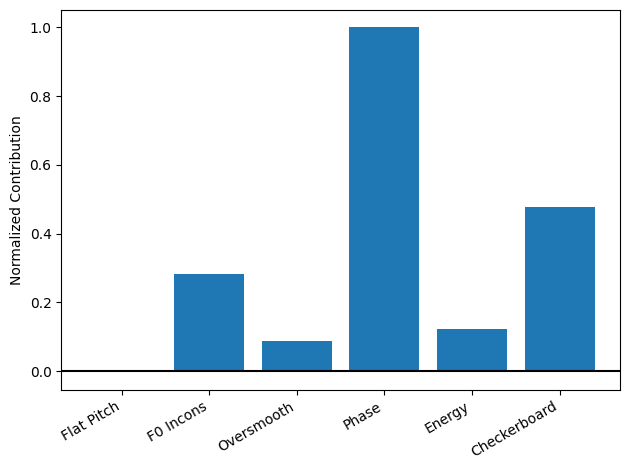


########################################################################################################################
#--------------------------------------------------------- A11 ---------------------------------------------------------#
########################################################################################################################

Loaded 1902 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 99.59%, EER: 2.91%
Real mean score: -1.3451
Fake mean score: 5.7190


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 41.55%, EER: 56.11%
Real mean score: 0.0069
Fake mean score: 0.0053

--- F0 Incons ---
AUC: 59.40%, EER: 43.36%
Real mean score: -0.0997
Fake mean score: 0.0312

--- Oversmooth ---
AUC: 78.64%, EER: 26.33%
Real mean score: -0.3767
Fake mean score: 0.5315

--- Phase ---
AUC: 77.57%, EER: 29.33%
Real mean score: -0.2523
Fake mean score: 0.3646

--- Energy ---
AUC: 99.14%, EER: 3.64%
Real mean score: -0.6369
Fake mean score: 4.5418



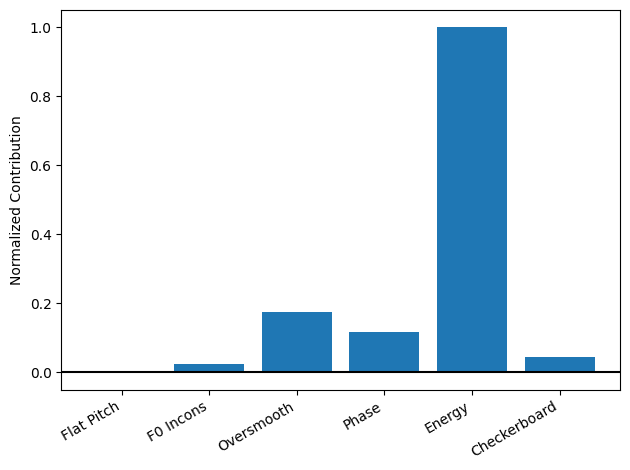


########################################################################################################################
#--------------------------------------------------------- A12 ---------------------------------------------------------#
########################################################################################################################

Loaded 1876 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 98.18%, EER: 4.71%
Real mean score: -1.3451
Fake mean score: 4.0364


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 45.30%, EER: 54.55%
Real mean score: 0.0069
Fake mean score: 0.0061

--- F0 Incons ---
AUC: 55.56%, EER: 46.76%
Real mean score: -0.0997
Fake mean score: -0.0180

--- Oversmooth ---
AUC: 45.60%, EER: 51.87%
Real mean score: -0.3768
Fake mean score: -0.5065

--- Phase ---
AUC: 58.07%, EER: 43.78%
Real mean score: -0.2523
Fake mean score: -0.0838

--- Energy ---
AUC: 99.25%, EER: 3.74%
Real mean score: -0.6369
Fake mean score: 4.547

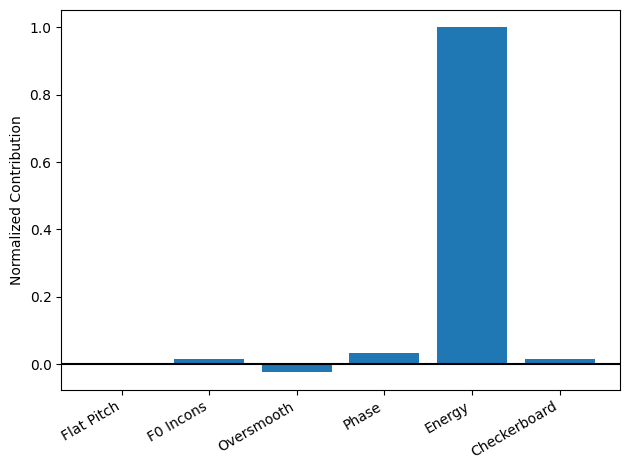

In [18]:
for a in generator_list:
    print(f"\n{'#'*120}")
    print(f"#{'-'*57} {a} {'-'*57}#")
    print(f"{'#'*120}\n")
    
    path = f"/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_asv19/6_experts/{a}"
    res = analyze_ensemble(path, expert_names=names)

## Test set: ASVspoof 5


In [28]:
generator_list = ['A01', 'A02', 'A03', 'A04', 'A05', 'A06', 'A07', 'A08', 'A09', 'A10', 'A11', 'A12', 'A14', 'A17', 'A19', 'A21', 'A22', 'A28', 'A29']    

Loaded 36544 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 69.95%, EER: 34.96%
Real mean score: -0.6835
Fake mean score: 0.1054


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 49.81%, EER: 49.81%
Real mean score: -0.0039
Fake mean score: -0.0041

--- F0 Incons ---
AUC: 47.74%, EER: 51.44%
Real mean score: 0.0297
Fake mean score: 0.0203

--- Oversmooth ---
AUC: 60.18%, EER: 42.28%
Real mean score: -0.1608
Fake mean score: 0.0279

--- Phase ---
AUC: 56.77%, EER: 45.19%
Real mean score: -0.1066
Fake mean score: 0.0022

--- Energy ---
AUC: 54.93%, EER: 45.66%
Real mean score: -0.0360
Fake mean score: -0.0342

--- Checkerboard ---
AUC: 65.69%, EER: 38.39%
Real mean score: -0.4060
Fake mean score: 0.0933



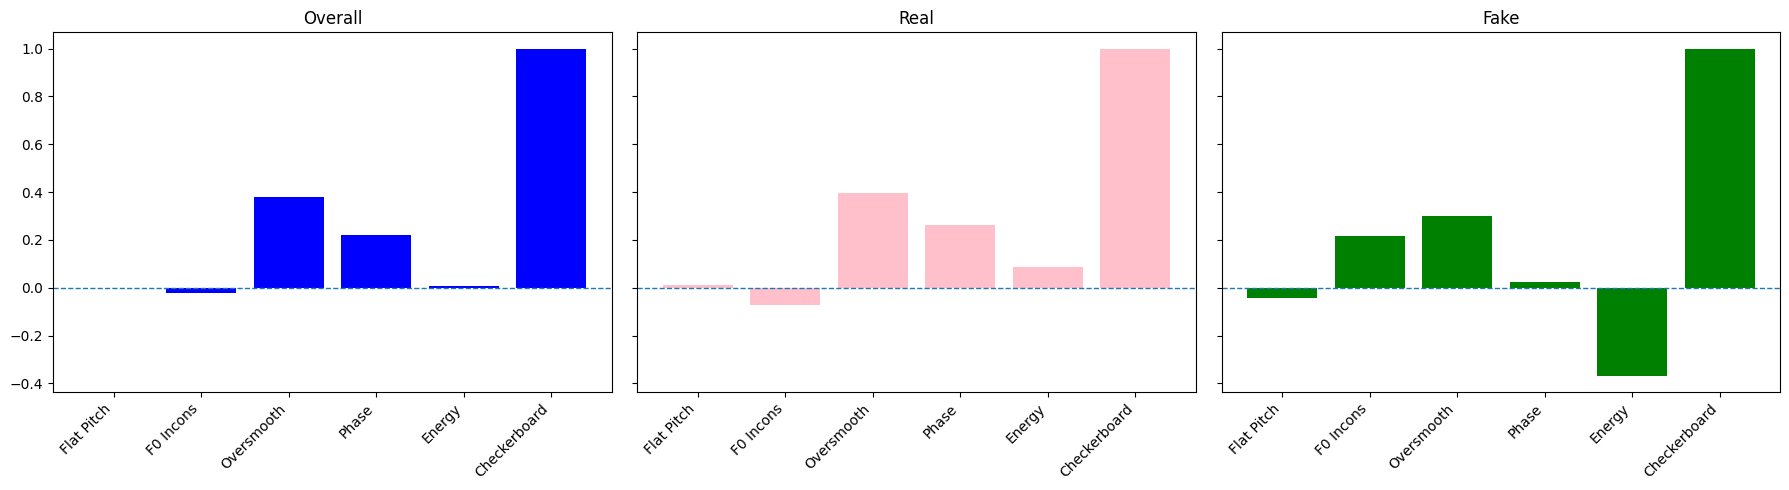

In [38]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv5/experts_trained_on_asv19/6_experts/ALL"
res = analyze_ensemble(rootpath, expert_names=names)


########################################################################################################################
#--------------------------------------------------------- A01 ---------------------------------------------------------#
########################################################################################################################

Loaded 1970 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 42.85%, EER: 57.06%
Real mean score: -0.1816
Fake mean score: -0.2334


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 50.85%, EER: 50.25%
Real mean score: -0.0135
Fake mean score: 0.0055

--- F0 Incons ---
AUC: 38.98%, EER: 59.46%
Real mean score: -0.0893
Fake mean score: -0.1217

--- Oversmooth ---
AUC: 49.54%, EER: 48.85%
Real mean score: -0.0482
Fake mean score: -0.0590

--- Phase ---
AUC: 48.86%, EER: 51.25%
Real mean score: -0.0142
Fake mean score: -0.0142

--- Energy ---
AUC: 24.30%, EER: 68.97%
Real mean score: -0.0149
Fake mean score: -

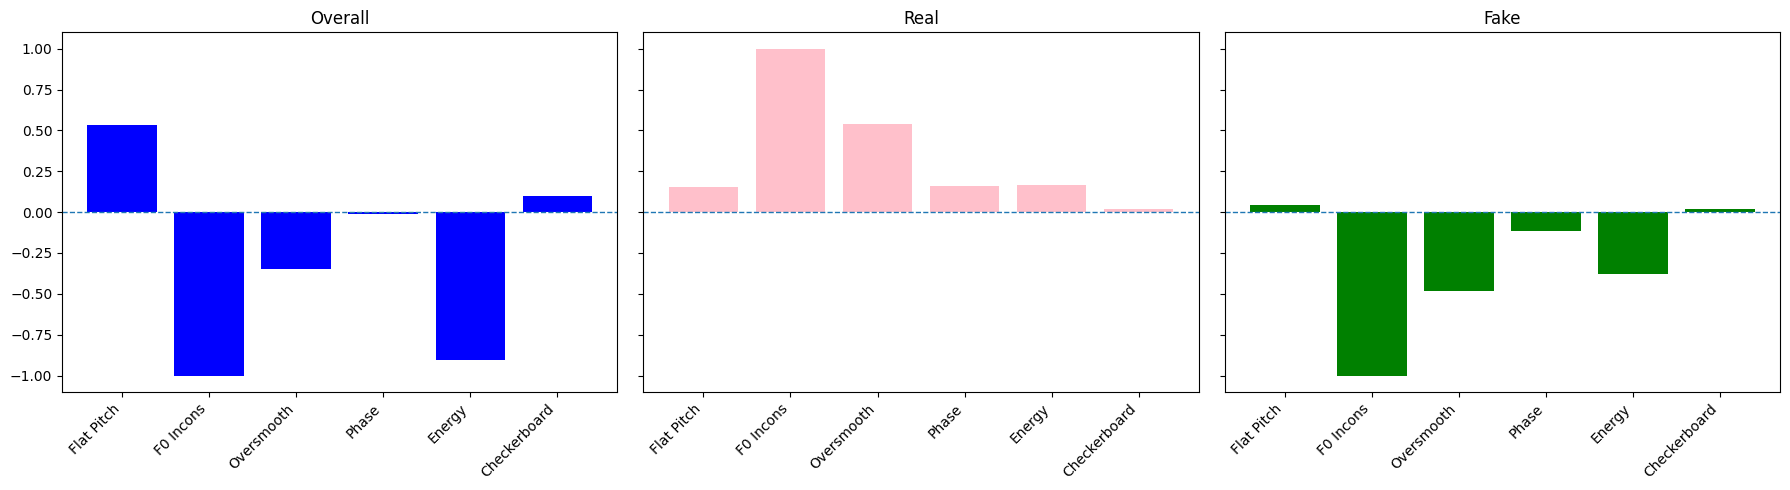


########################################################################################################################
#--------------------------------------------------------- A02 ---------------------------------------------------------#
########################################################################################################################

Loaded 1971 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 42.79%, EER: 57.16%
Real mean score: -0.1817
Fake mean score: -0.2541


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 53.10%, EER: 48.50%
Real mean score: -0.0135
Fake mean score: 0.0153

--- F0 Incons ---
AUC: 38.15%, EER: 59.42%
Real mean score: -0.0893
Fake mean score: -0.1447

--- Oversmooth ---
AUC: 49.17%, EER: 49.02%
Real mean score: -0.0483
Fake mean score: -0.0660

--- Phase ---
AUC: 48.12%, EER: 51.60%
Real mean score: -0.0142
Fake mean score: -0.0145

--- Energy ---
AUC: 24.07%, EER: 69.41%
Real mean score: -0.0149
Fake mean score: -

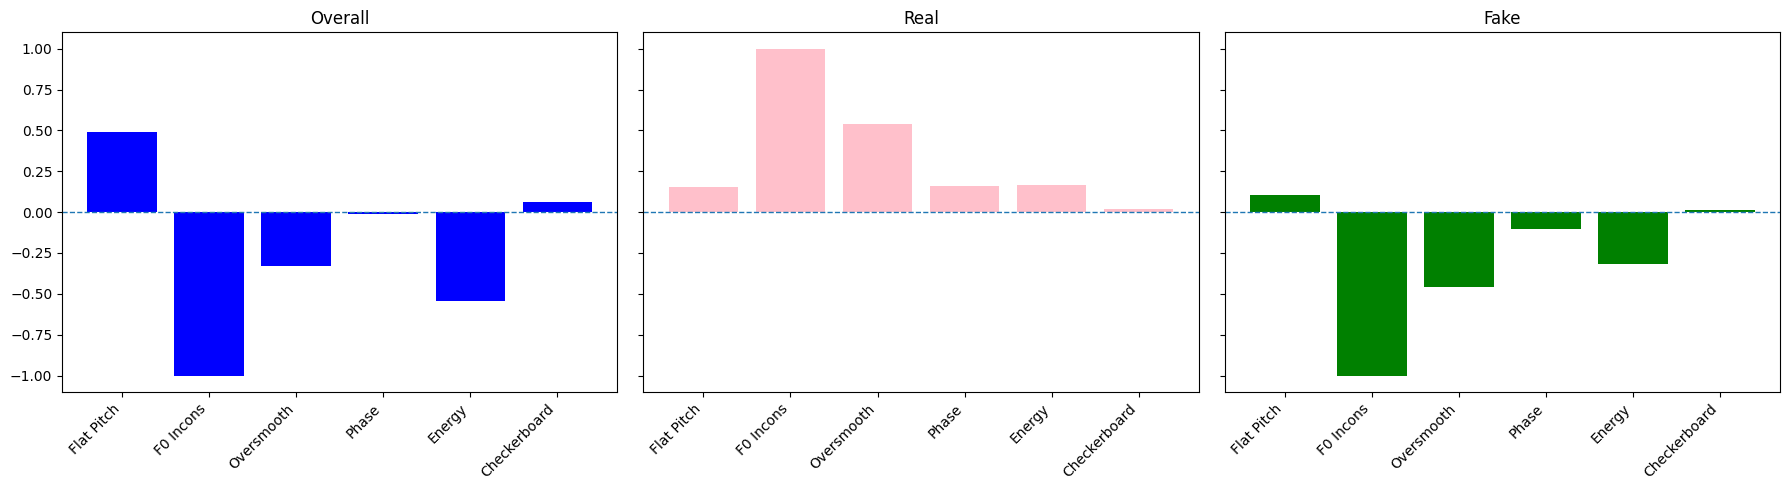


########################################################################################################################
#--------------------------------------------------------- A03 ---------------------------------------------------------#
########################################################################################################################

Loaded 1971 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 39.10%, EER: 58.60%
Real mean score: -0.1816
Fake mean score: -0.3004


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 49.88%, EER: 50.77%
Real mean score: -0.0135
Fake mean score: -0.0059

--- F0 Incons ---
AUC: 36.51%, EER: 60.30%
Real mean score: -0.0893
Fake mean score: -0.1714

--- Oversmooth ---
AUC: 50.36%, EER: 48.51%
Real mean score: -0.0482
Fake mean score: -0.0630

--- Phase ---
AUC: 40.72%, EER: 57.36%
Real mean score: -0.0142
Fake mean score: -0.0168

--- Energy ---
AUC: 24.92%, EER: 69.52%
Real mean score: -0.0149
Fake mean score: 

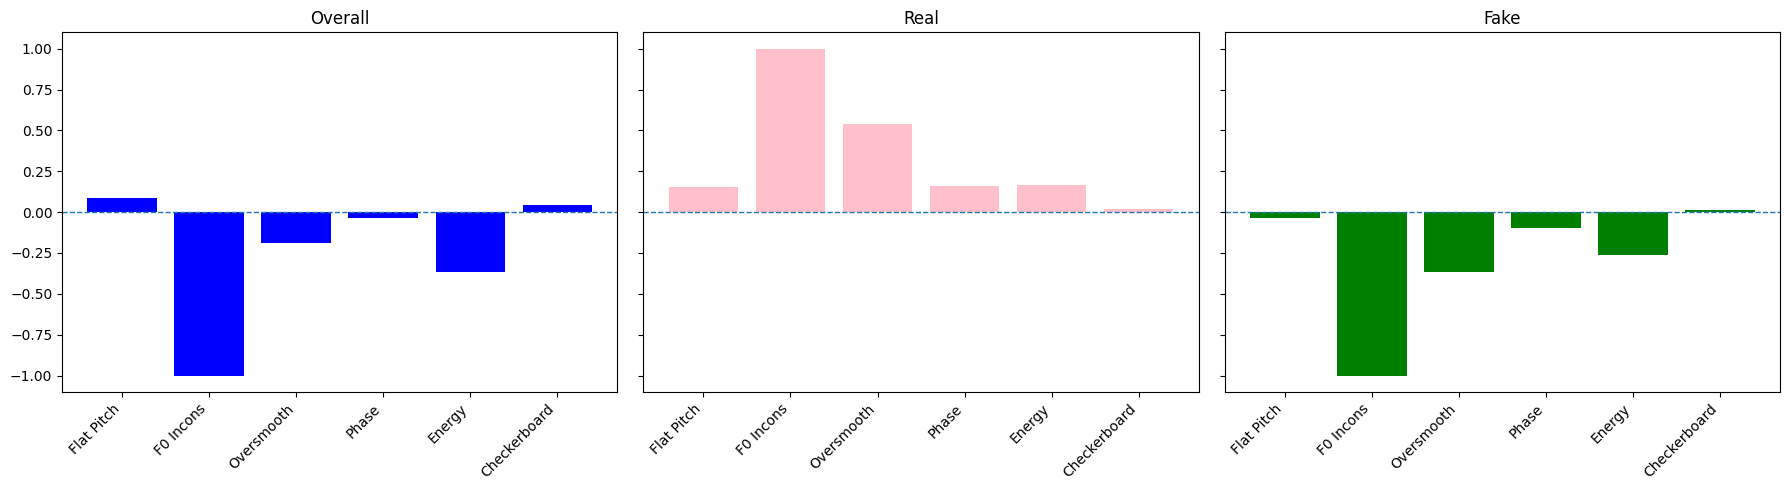


########################################################################################################################
#--------------------------------------------------------- A04 ---------------------------------------------------------#
########################################################################################################################

Loaded 1962 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 45.36%, EER: 55.41%
Real mean score: -0.1821
Fake mean score: -0.2055


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 51.54%, EER: 49.75%
Real mean score: -0.0135
Fake mean score: 0.0095

--- F0 Incons ---
AUC: 38.07%, EER: 59.74%
Real mean score: -0.0893
Fake mean score: -0.1279

--- Oversmooth ---
AUC: 52.06%, EER: 49.12%
Real mean score: -0.0487
Fake mean score: -0.0316

--- Phase ---
AUC: 36.23%, EER: 60.35%
Real mean score: -0.0142
Fake mean score: -0.0184

--- Energy ---
AUC: 30.13%, EER: 65.81%
Real mean score: -0.0149
Fake mean score: -

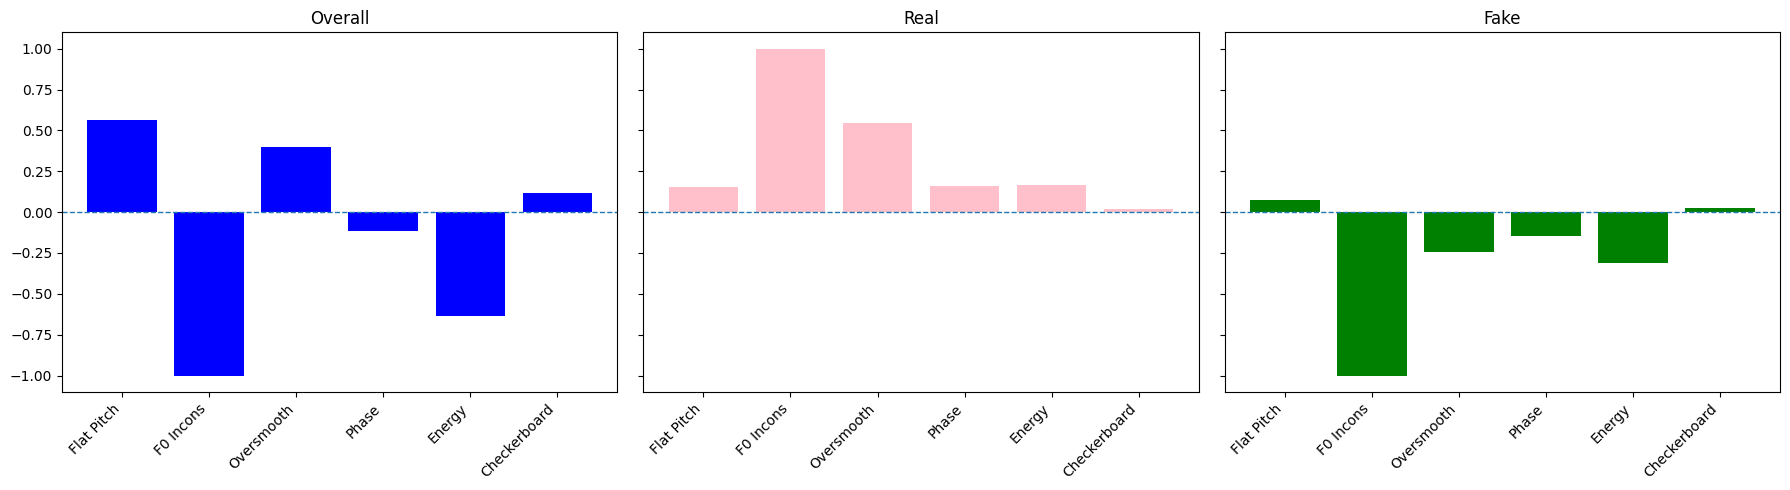


########################################################################################################################
#--------------------------------------------------------- A05 ---------------------------------------------------------#
########################################################################################################################

Loaded 1967 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 43.99%, EER: 55.92%
Real mean score: -0.1819
Fake mean score: -0.2210


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 49.71%, EER: 51.08%
Real mean score: -0.0135
Fake mean score: 0.0007

--- F0 Incons ---
AUC: 40.49%, EER: 58.29%
Real mean score: -0.0893
Fake mean score: -0.1120

--- Oversmooth ---
AUC: 48.85%, EER: 50.50%
Real mean score: -0.0485
Fake mean score: -0.0539

--- Phase ---
AUC: 31.63%, EER: 63.75%
Real mean score: -0.0142
Fake mean score: -0.0200

--- Energy ---
AUC: 31.48%, EER: 65.16%
Real mean score: -0.0149
Fake mean score: -

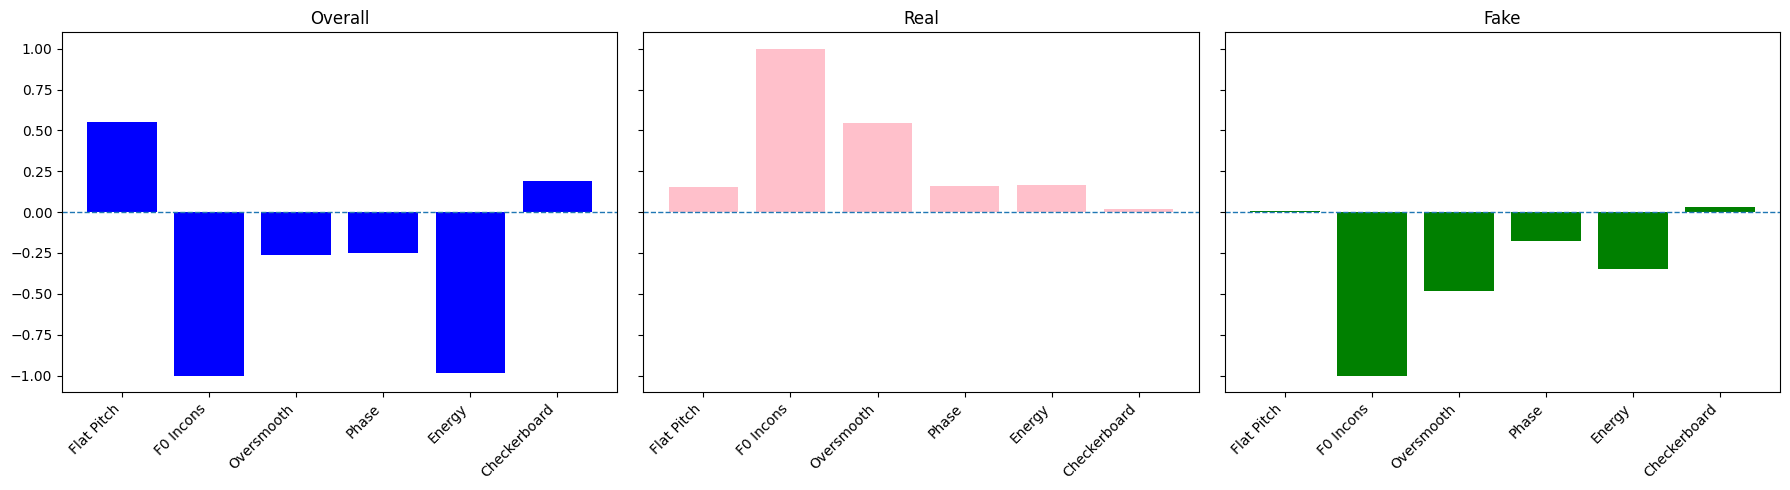


########################################################################################################################
#--------------------------------------------------------- A06 ---------------------------------------------------------#
########################################################################################################################

Loaded 1967 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 43.94%, EER: 56.02%
Real mean score: -0.1820
Fake mean score: -0.2285


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 48.65%, EER: 52.01%
Real mean score: -0.0135
Fake mean score: -0.0112

--- F0 Incons ---
AUC: 41.58%, EER: 55.61%
Real mean score: -0.0893
Fake mean score: -0.1083

--- Oversmooth ---
AUC: 50.10%, EER: 49.33%
Real mean score: -0.0486
Fake mean score: -0.0526

--- Phase ---
AUC: 39.09%, EER: 57.53%
Real mean score: -0.0142
Fake mean score: -0.0173

--- Energy ---
AUC: 26.48%, EER: 69.41%
Real mean score: -0.0149
Fake mean score: 

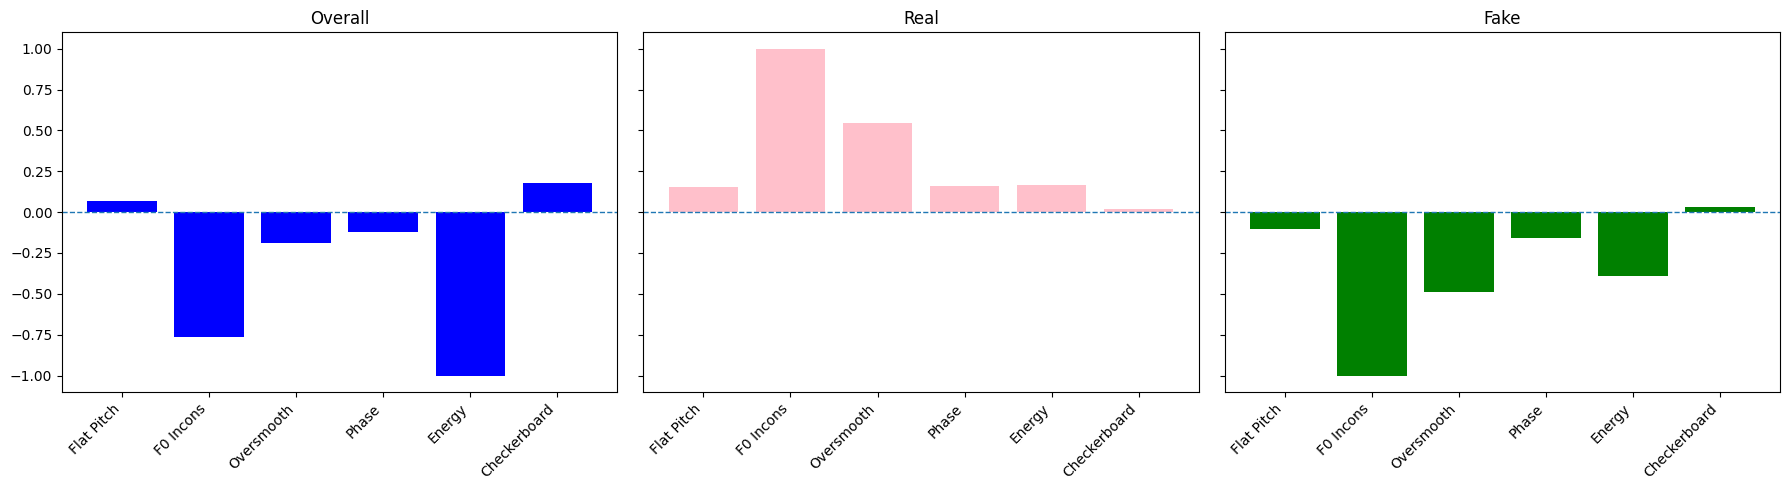


########################################################################################################################
#--------------------------------------------------------- A07 ---------------------------------------------------------#
########################################################################################################################

Loaded 1970 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 39.96%, EER: 56.46%
Real mean score: -0.1821
Fake mean score: -0.3189


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 42.42%, EER: 55.72%
Real mean score: -0.0135
Fake mean score: -0.0608

--- F0 Incons ---
AUC: 53.69%, EER: 45.11%
Real mean score: -0.0893
Fake mean score: -0.1389

--- Oversmooth ---
AUC: 57.38%, EER: 41.81%
Real mean score: -0.0487
Fake mean score: -0.0527

--- Phase ---
AUC: 28.52%, EER: 66.47%
Real mean score: -0.0142
Fake mean score: -0.0204

--- Energy ---
AUC: 19.58%, EER: 72.97%
Real mean score: -0.0149
Fake mean score: 

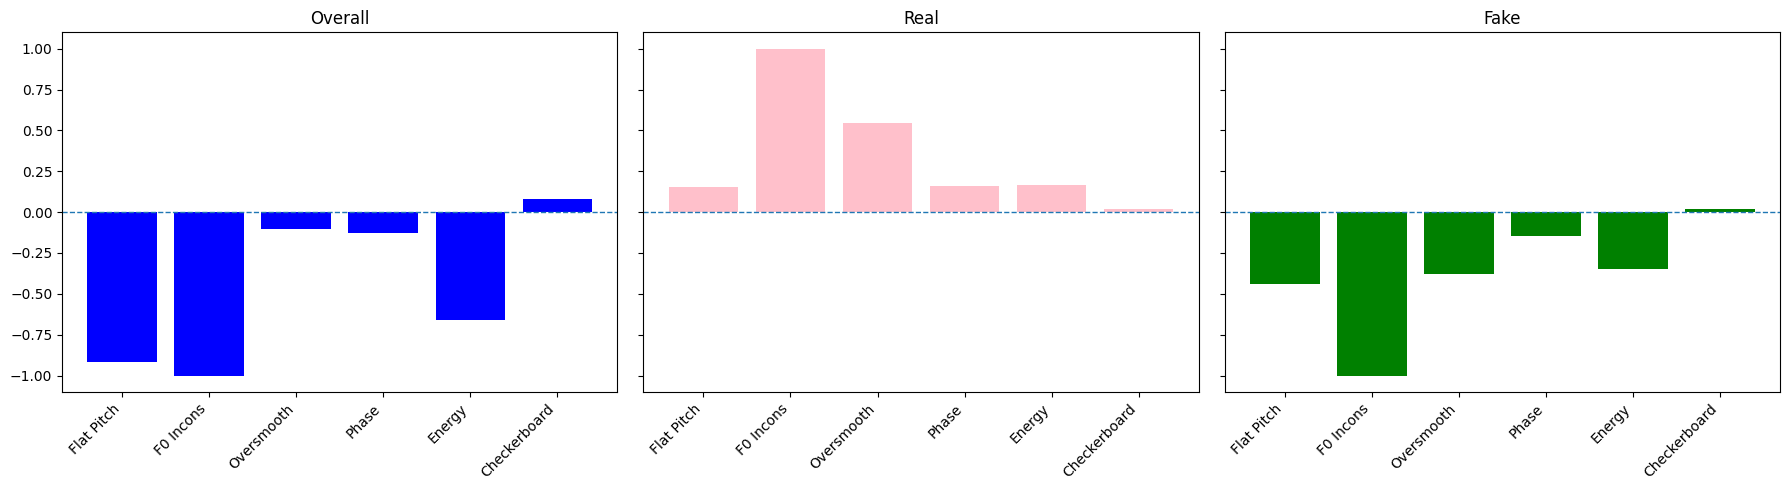


########################################################################################################################
#--------------------------------------------------------- A08 ---------------------------------------------------------#
########################################################################################################################

Loaded 1970 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 34.43%, EER: 61.38%
Real mean score: -0.1816
Fake mean score: -0.3965


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 36.95%, EER: 59.76%
Real mean score: -0.0135
Fake mean score: -0.1188

--- F0 Incons ---
AUC: 49.14%, EER: 48.25%
Real mean score: -0.0893
Fake mean score: -0.1556

--- Oversmooth ---
AUC: 42.00%, EER: 56.06%
Real mean score: -0.0482
Fake mean score: -0.0662

--- Phase ---
AUC: 50.92%, EER: 49.23%
Real mean score: -0.0142
Fake mean score: -0.0138

--- Energy ---
AUC: 29.75%, EER: 65.91%
Real mean score: -0.0149
Fake mean score: 

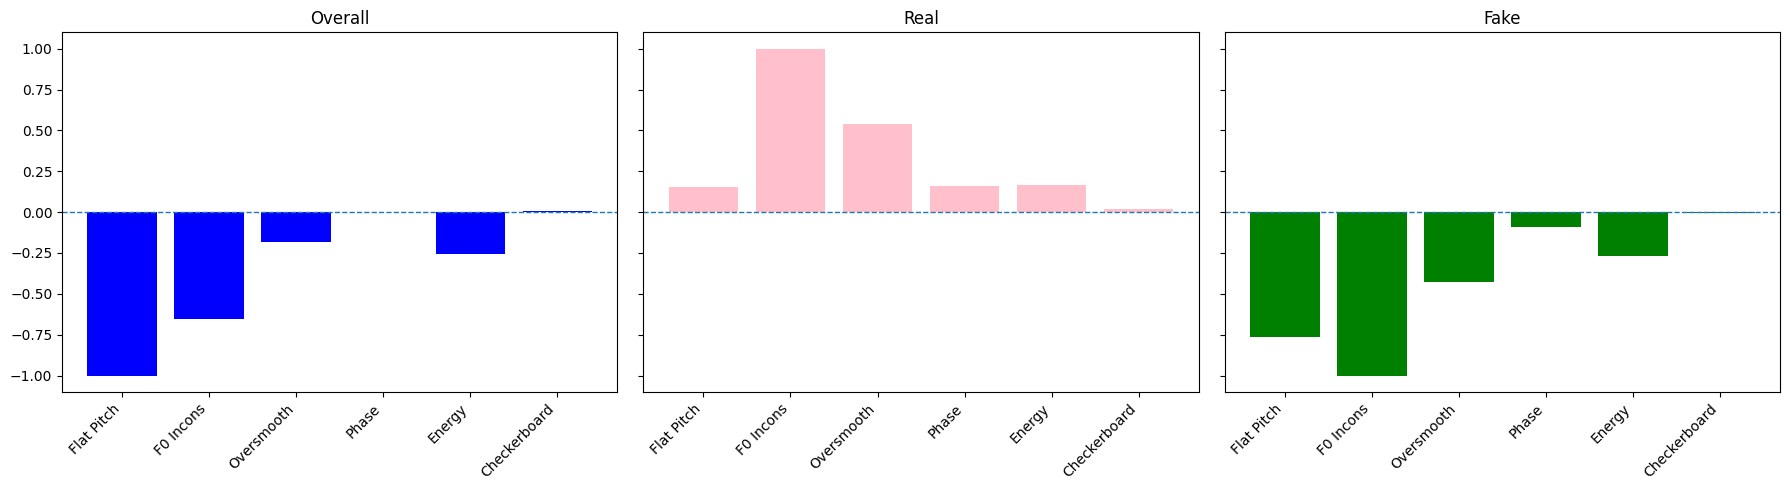


########################################################################################################################
#--------------------------------------------------------- A09 ---------------------------------------------------------#
########################################################################################################################

Loaded 1971 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 45.25%, EER: 51.30%
Real mean score: -0.1816
Fake mean score: -0.3166


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 42.22%, EER: 55.20%
Real mean score: -0.0135
Fake mean score: -0.1042

--- F0 Incons ---
AUC: 52.06%, EER: 46.90%
Real mean score: -0.0893
Fake mean score: -0.1450

--- Oversmooth ---
AUC: 39.91%, EER: 57.88%
Real mean score: -0.0482
Fake mean score: -0.0715

--- Phase ---
AUC: 36.48%, EER: 59.40%
Real mean score: -0.0142
Fake mean score: -0.0182

--- Energy ---
AUC: 75.46%, EER: 30.59%
Real mean score: -0.0149
Fake mean score: 

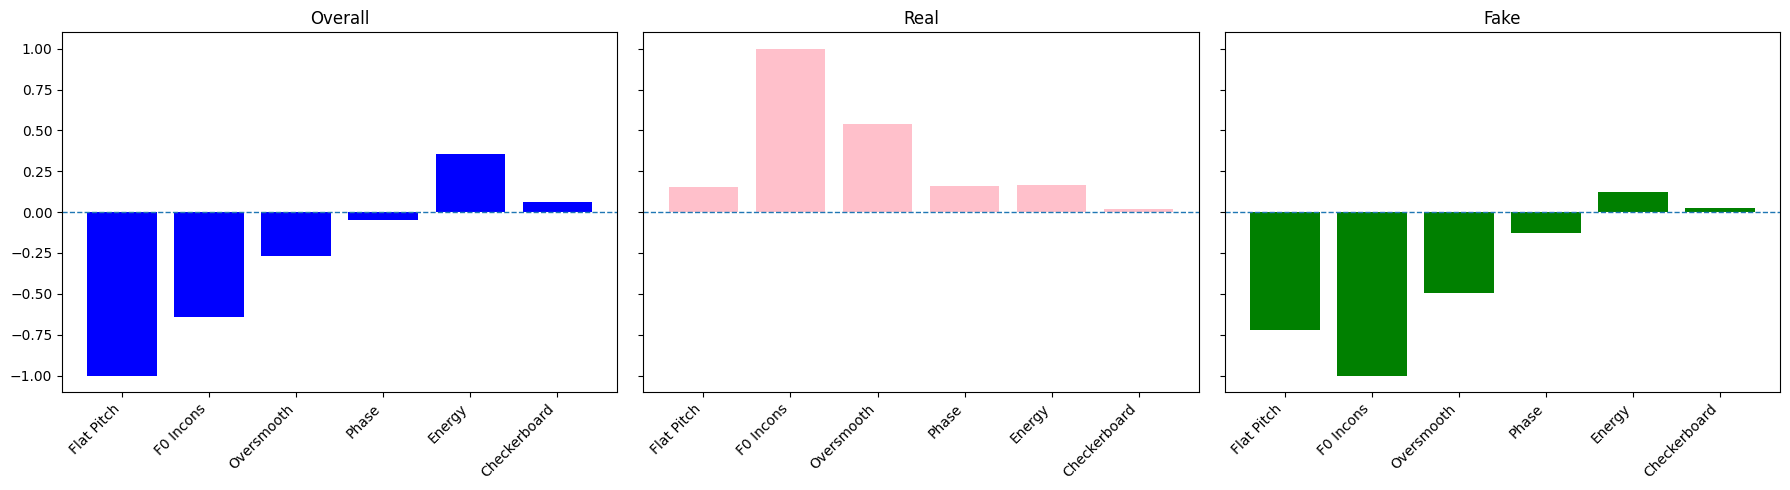


########################################################################################################################
#--------------------------------------------------------- A10 ---------------------------------------------------------#
########################################################################################################################

Loaded 1971 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 46.31%, EER: 51.50%
Real mean score: -0.1820
Fake mean score: -0.3010


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 44.16%, EER: 53.86%
Real mean score: -0.0135
Fake mean score: -0.0892

--- F0 Incons ---
AUC: 50.69%, EER: 47.60%
Real mean score: -0.0893
Fake mean score: -0.1508

--- Oversmooth ---
AUC: 41.80%, EER: 56.85%
Real mean score: -0.0487
Fake mean score: -0.0634

--- Phase ---
AUC: 35.97%, EER: 60.45%
Real mean score: -0.0142
Fake mean score: -0.0183

--- Energy ---
AUC: 75.54%, EER: 30.59%
Real mean score: -0.0149
Fake mean score: 

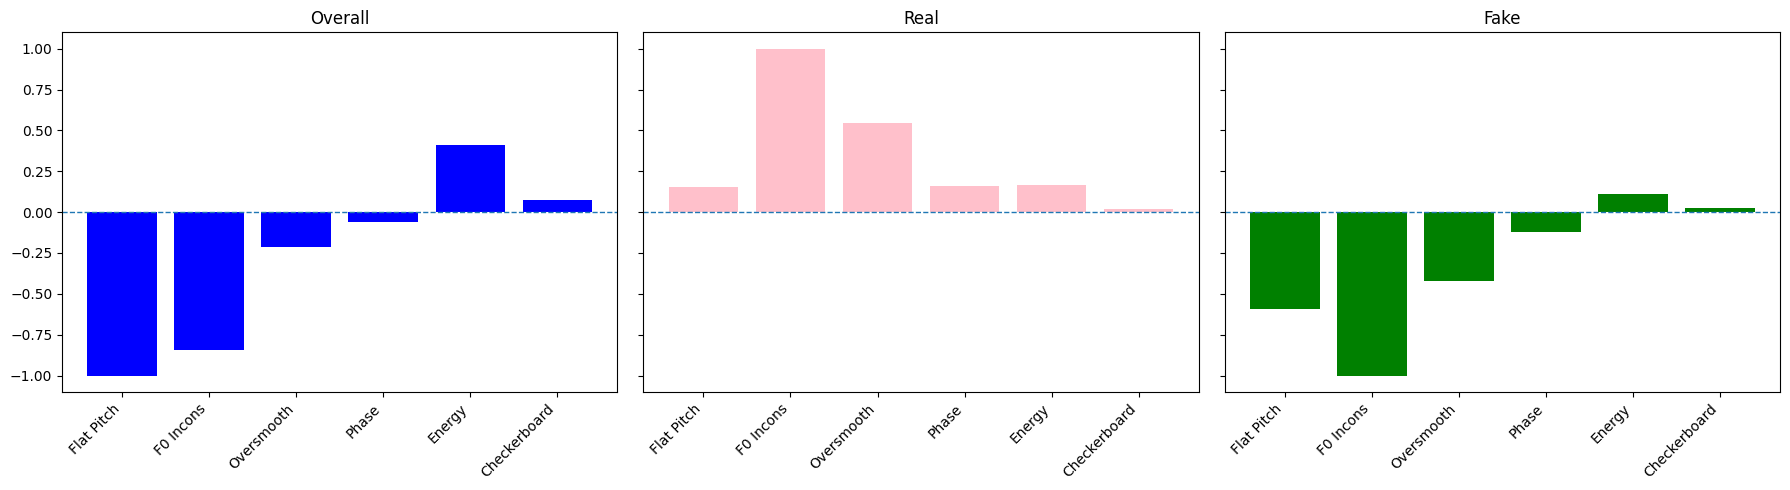


########################################################################################################################
#--------------------------------------------------------- A11 ---------------------------------------------------------#
########################################################################################################################

Loaded 1945 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 51.02%, EER: 51.18%
Real mean score: -0.1815
Fake mean score: -0.1358


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 42.92%, EER: 56.33%
Real mean score: -0.0135
Fake mean score: -0.0741

--- F0 Incons ---
AUC: 49.03%, EER: 49.69%
Real mean score: -0.0893
Fake mean score: -0.0913

--- Oversmooth ---
AUC: 43.82%, EER: 55.61%
Real mean score: -0.0481
Fake mean score: -0.0560

--- Phase ---
AUC: 63.51%, EER: 40.16%
Real mean score: -0.0142
Fake mean score: -0.0099

--- Energy ---
AUC: 63.39%, EER: 46.61%
Real mean score: -0.0149
Fake mean score: 

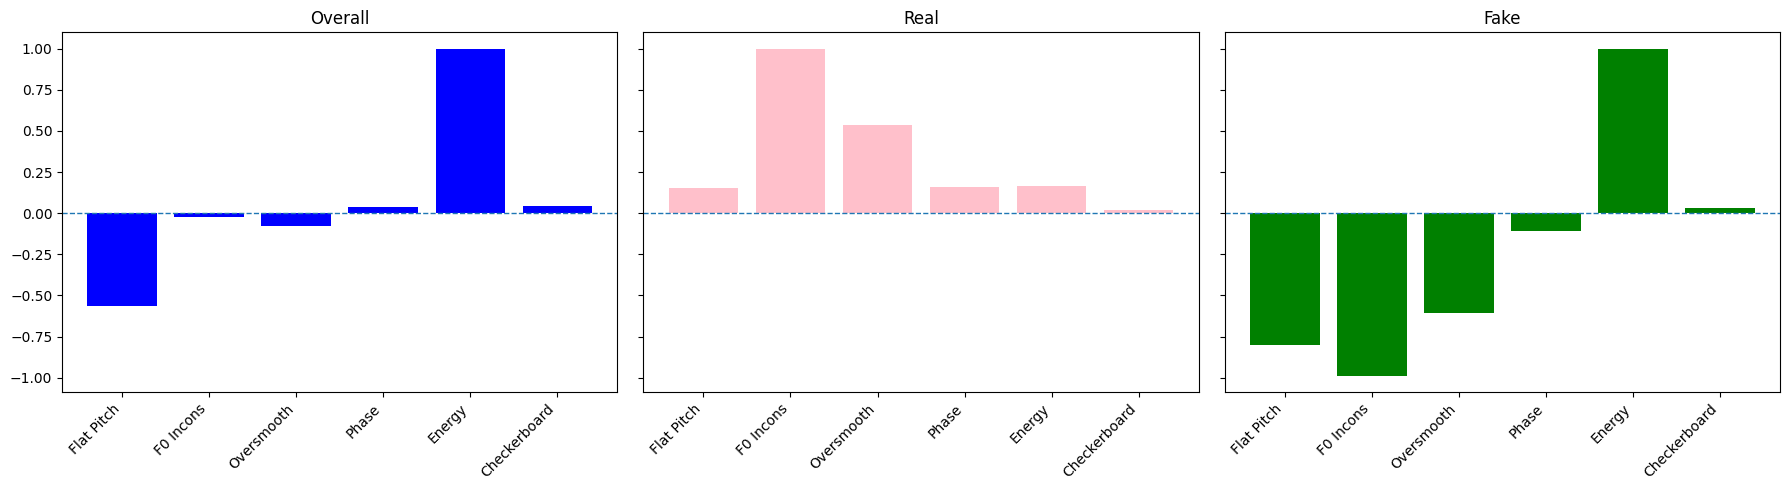


########################################################################################################################
#--------------------------------------------------------- A12 ---------------------------------------------------------#
########################################################################################################################

Loaded 1969 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 86.35%, EER: 20.24%
Real mean score: -0.1816
Fake mean score: 0.7659


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 63.91%, EER: 39.75%
Real mean score: -0.0135
Fake mean score: 0.1137

--- F0 Incons ---
AUC: 77.57%, EER: 26.95%
Real mean score: -0.0893
Fake mean score: 0.5642

--- Oversmooth ---
AUC: 78.59%, EER: 28.94%
Real mean score: -0.0482
Fake mean score: 0.1093

--- Phase ---
AUC: 80.35%, EER: 27.60%
Real mean score: -0.0142
Fake mean score: -0.0034

--- Energy ---
AUC: 49.68%, EER: 50.98%
Real mean score: -0.0149
Fake mean score: -0.0

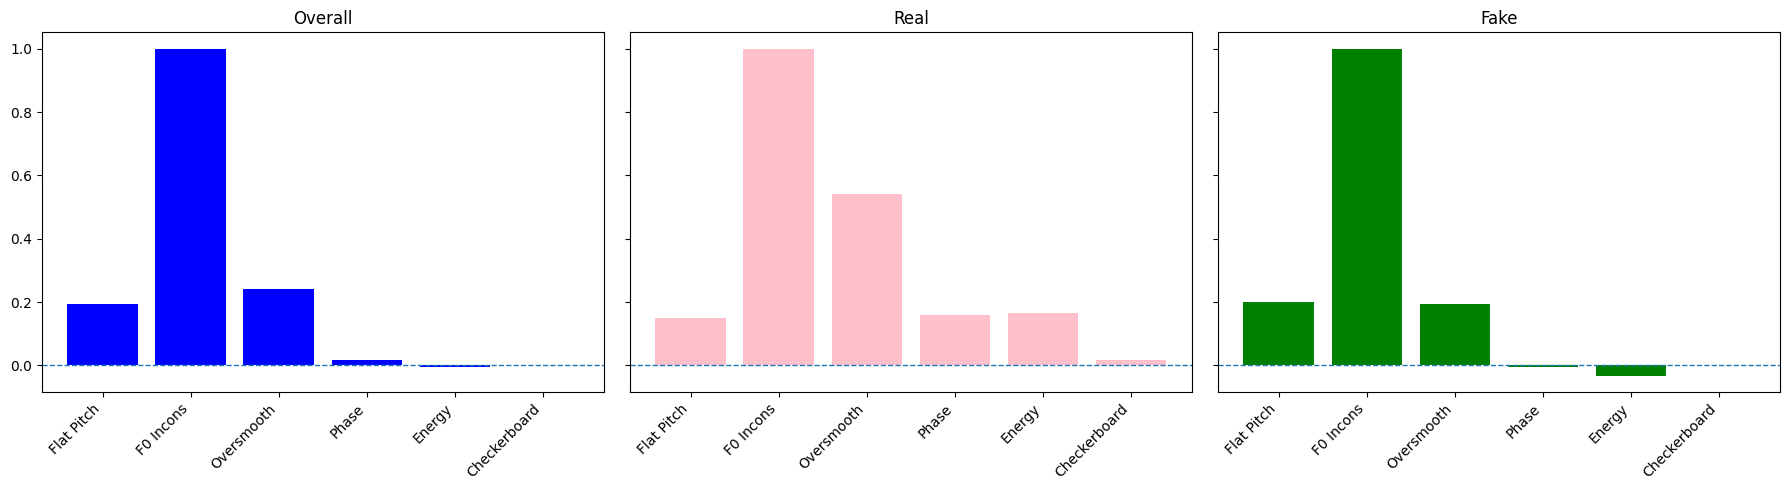


########################################################################################################################
#--------------------------------------------------------- A14 ---------------------------------------------------------#
########################################################################################################################

Loaded 1096 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 46.19%, EER: 52.42%
Real mean score: -0.1816
Fake mean score: -0.2387


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 49.30%, EER: 52.11%
Real mean score: -0.0135
Fake mean score: -0.0587

--- F0 Incons ---
AUC: 56.63%, EER: 44.00%
Real mean score: -0.0893
Fake mean score: -0.0836

--- Oversmooth ---
AUC: 44.98%, EER: 56.80%
Real mean score: -0.0482
Fake mean score: -0.0372

--- Phase ---
AUC: 40.39%, EER: 56.80%
Real mean score: -0.0142
Fake mean score: -0.0167

--- Energy ---
AUC: 23.44%, EER: 71.37%
Real mean score: -0.0149
Fake mean score: 

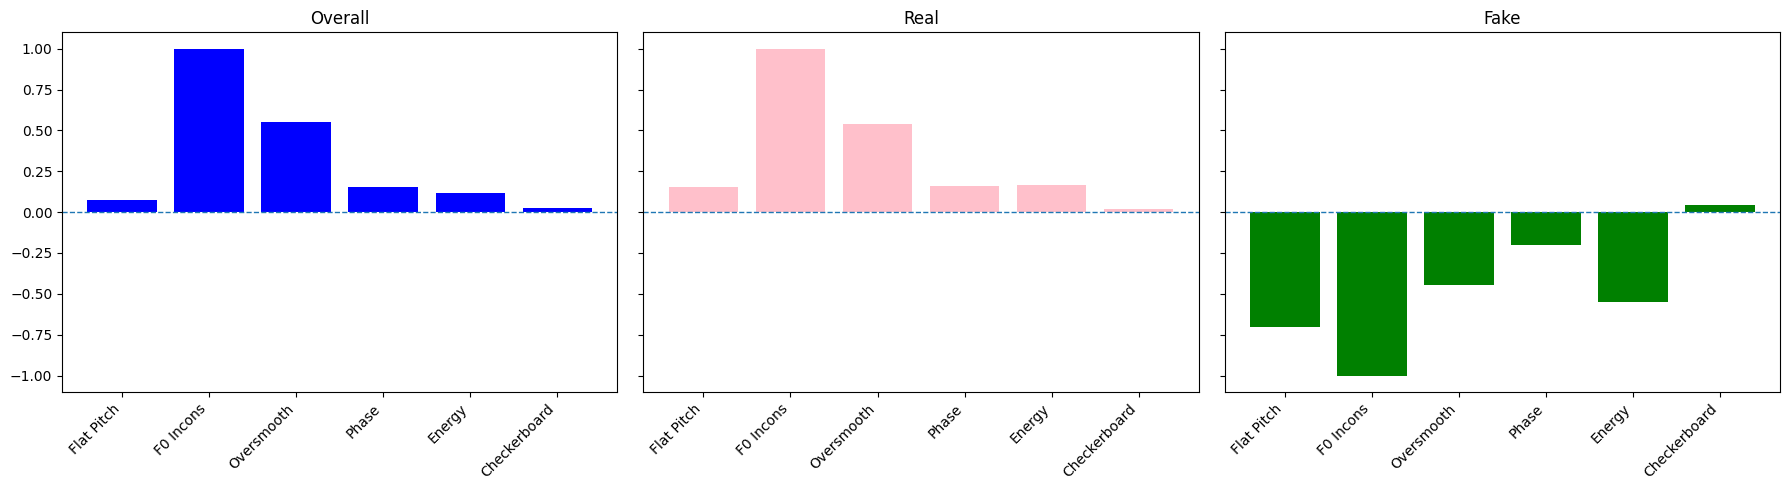


########################################################################################################################
#--------------------------------------------------------- A17 ---------------------------------------------------------#
########################################################################################################################

Loaded 1967 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 48.87%, EER: 51.31%
Real mean score: -0.1818
Fake mean score: -0.2014


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 54.83%, EER: 47.58%
Real mean score: -0.0135
Fake mean score: 0.0517

--- F0 Incons ---
AUC: 43.43%, EER: 53.55%
Real mean score: -0.0893
Fake mean score: -0.1723

--- Oversmooth ---
AUC: 47.54%, EER: 52.41%
Real mean score: -0.0484
Fake mean score: -0.0593

--- Phase ---
AUC: 43.15%, EER: 55.42%
Real mean score: -0.0142
Fake mean score: -0.0159

--- Energy ---
AUC: 56.37%, EER: 45.98%
Real mean score: -0.0149
Fake mean score: -

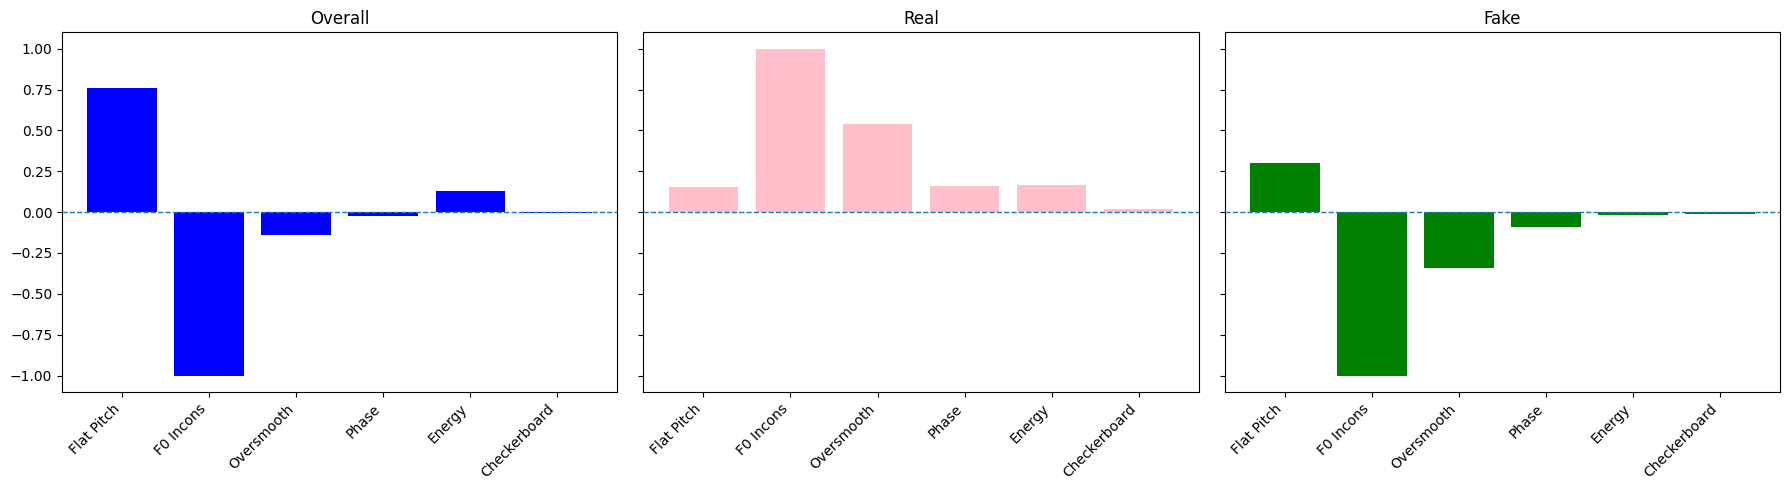


########################################################################################################################
#--------------------------------------------------------- A19 ---------------------------------------------------------#
########################################################################################################################

Loaded 1925 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 67.68%, EER: 39.94%
Real mean score: -0.1821
Fake mean score: 0.1794


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 64.78%, EER: 39.55%
Real mean score: -0.0135
Fake mean score: 0.1085

--- F0 Incons ---
AUC: 55.37%, EER: 49.27%
Real mean score: -0.0893
Fake mean score: 0.1121

--- Oversmooth ---
AUC: 60.53%, EER: 42.56%
Real mean score: -0.0487
Fake mean score: -0.0098

--- Phase ---
AUC: 60.67%, EER: 42.22%
Real mean score: -0.0142
Fake mean score: -0.0107

--- Energy ---
AUC: 51.32%, EER: 48.85%
Real mean score: -0.0149
Fake mean score: -0.

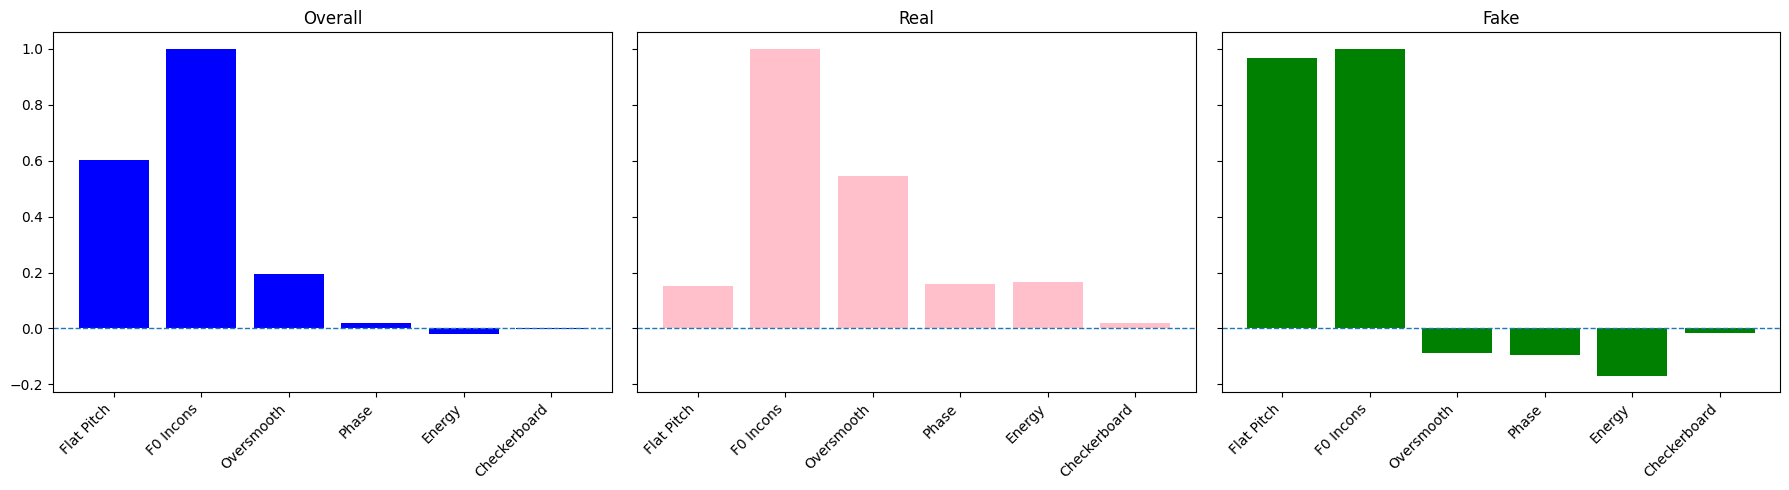


########################################################################################################################
#--------------------------------------------------------- A21 ---------------------------------------------------------#
########################################################################################################################

Loaded 1960 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 59.36%, EER: 40.58%
Real mean score: -0.1815
Fake mean score: -0.1212


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 57.10%, EER: 46.41%
Real mean score: -0.0135
Fake mean score: 0.0646

--- F0 Incons ---
AUC: 60.90%, EER: 39.75%
Real mean score: -0.0893
Fake mean score: -0.1163

--- Oversmooth ---
AUC: 44.59%, EER: 53.35%
Real mean score: -0.0481
Fake mean score: -0.0707

--- Phase ---
AUC: 35.97%, EER: 59.35%
Real mean score: -0.0142
Fake mean score: -0.0181

--- Energy ---
AUC: 74.18%, EER: 32.65%
Real mean score: -0.0149
Fake mean score: 0

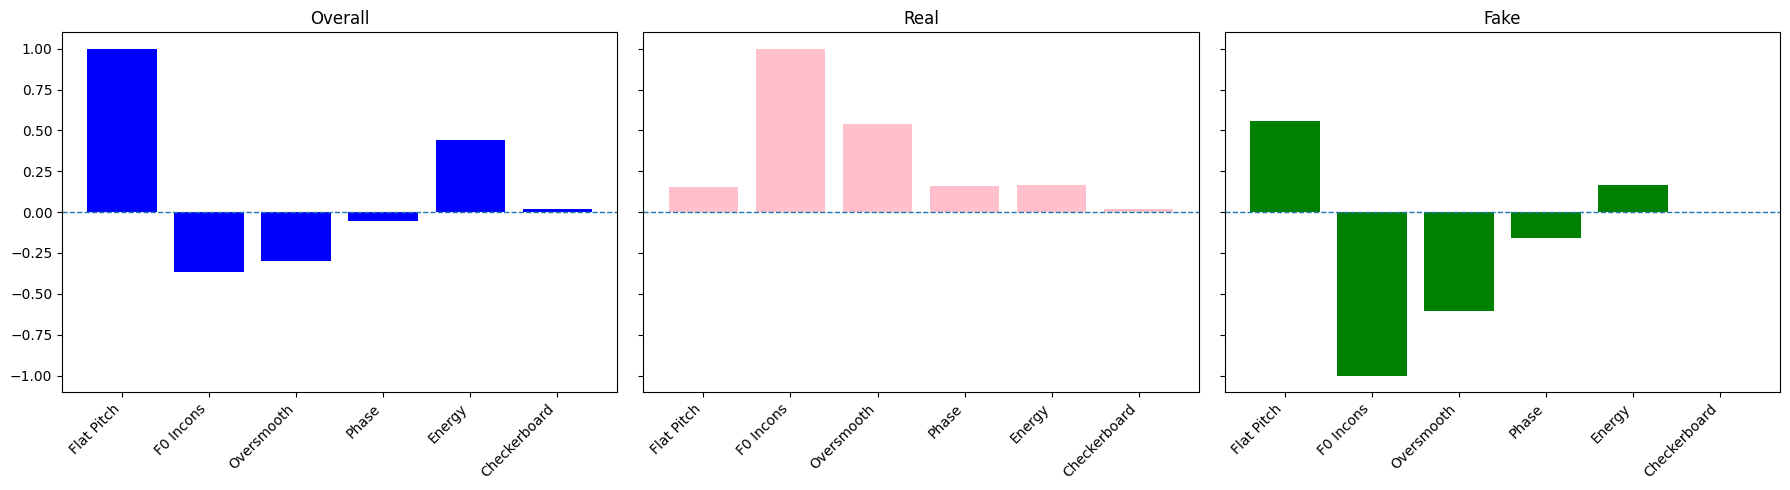


########################################################################################################################
#--------------------------------------------------------- A22 ---------------------------------------------------------#
########################################################################################################################

Loaded 1955 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 55.84%, EER: 45.63%
Real mean score: -0.1820
Fake mean score: -0.1212


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 51.25%, EER: 48.68%
Real mean score: -0.0135
Fake mean score: 0.0104

--- F0 Incons ---
AUC: 46.76%, EER: 51.80%
Real mean score: -0.0893
Fake mean score: -0.1147

--- Oversmooth ---
AUC: 49.91%, EER: 49.33%
Real mean score: -0.0486
Fake mean score: -0.0457

--- Phase ---
AUC: 32.12%, EER: 63.44%
Real mean score: -0.0142
Fake mean score: -0.0195

--- Energy ---
AUC: 77.31%, EER: 29.07%
Real mean score: -0.0149
Fake mean score: 0

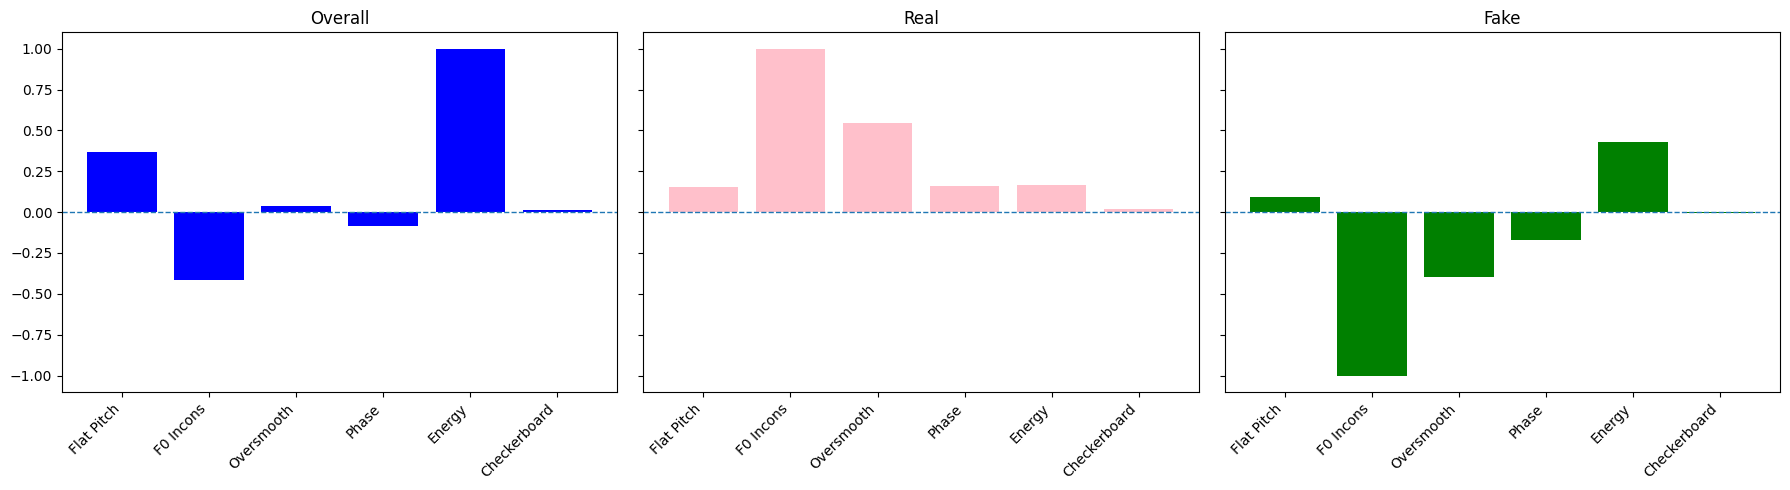


########################################################################################################################
#--------------------------------------------------------- A28 ---------------------------------------------------------#
########################################################################################################################

Loaded 1946 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 53.11%, EER: 49.02%
Real mean score: -0.1821
Fake mean score: -0.1427


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 54.92%, EER: 47.38%
Real mean score: -0.0135
Fake mean score: 0.0460

--- F0 Incons ---
AUC: 48.07%, EER: 49.95%
Real mean score: -0.0893
Fake mean score: -0.1268

--- Oversmooth ---
AUC: 50.76%, EER: 50.15%
Real mean score: -0.0487
Fake mean score: -0.0436

--- Phase ---
AUC: 39.90%, EER: 56.82%
Real mean score: -0.0142
Fake mean score: -0.0171

--- Energy ---
AUC: 61.28%, EER: 43.90%
Real mean score: -0.0149
Fake mean score: 0

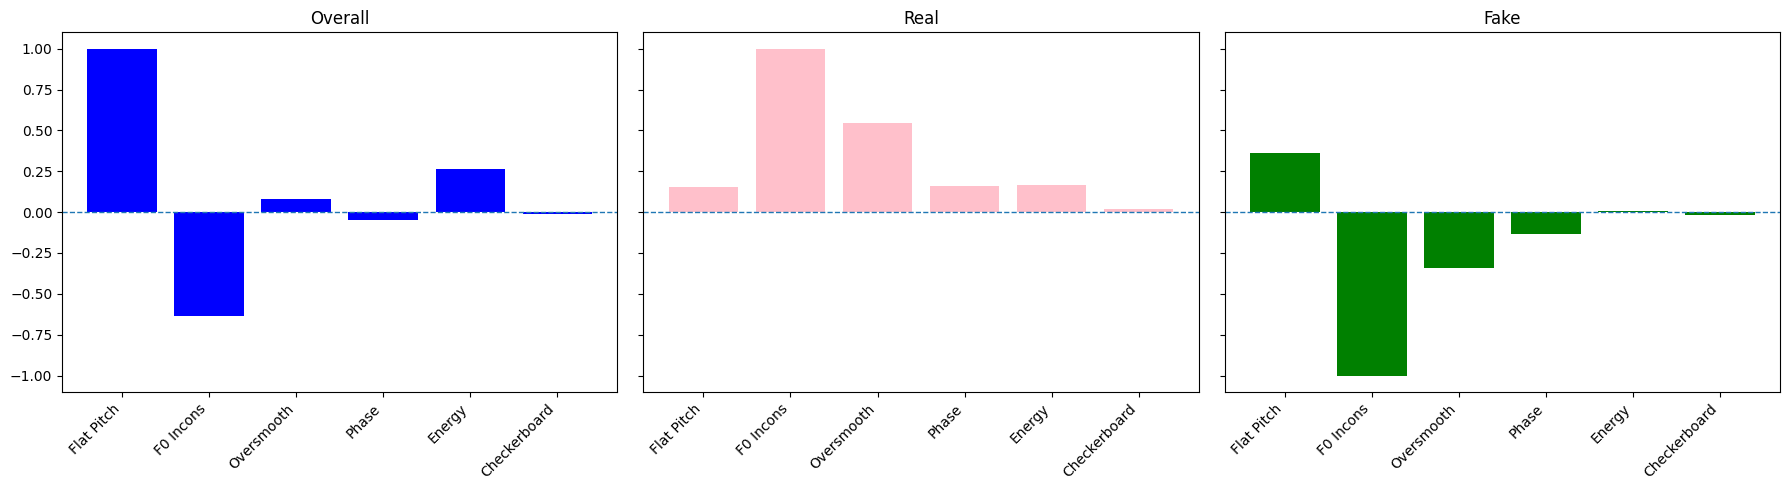


########################################################################################################################
#--------------------------------------------------------- A29 ---------------------------------------------------------#
########################################################################################################################

Loaded 1936 samples

#--------- OVERALL ENSEMBLE ---------#

AUC: 48.79%, EER: 51.61%
Real mean score: -0.1818
Fake mean score: -0.1891


#------------ PER EXPERT ------------#

--- Flat Pitch ---
AUC: 57.24%, EER: 46.76%
Real mean score: -0.0135
Fake mean score: 0.0702

--- F0 Incons ---
AUC: 44.39%, EER: 52.75%
Real mean score: -0.0893
Fake mean score: -0.1591

--- Oversmooth ---
AUC: 46.09%, EER: 52.42%
Real mean score: -0.0484
Fake mean score: -0.0651

--- Phase ---
AUC: 30.92%, EER: 63.34%
Real mean score: -0.0142
Fake mean score: -0.0197

--- Energy ---
AUC: 51.07%, EER: 48.92%
Real mean score: -0.0149
Fake mean score: -

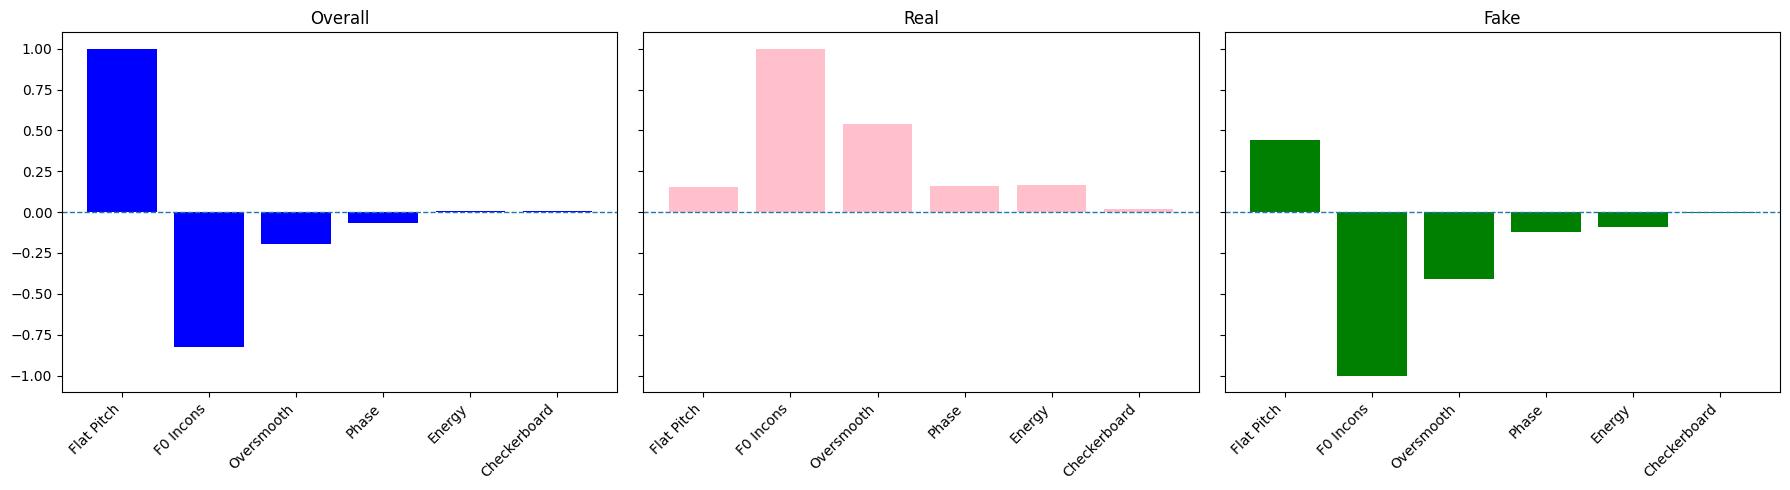

In [33]:
for a in generator_list:
    print(f"\n{'#'*120}")
    print(f"#{'-'*57} {a} {'-'*57}#")
    print(f"{'#'*120}\n")
    
    path = f"/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv5/experts_trained_on_asv19/6_experts/{a}"
    res = analyze_ensemble(path, expert_names=names)